In [1]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import copy
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [16]:

class Resnet18_LSTM_Model(nn.Module):
    def __init__(self, num_classes):
        super(Resnet18_LSTM_Model, self).__init__()
        # CNN feature extractor
        self.cnn = models.resnet18(pretrained=True)
        self.cnn.fc = nn.Identity()
        self.cnn.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        
        # LSTM sequence model
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, num_layers=1, batch_first=True)
        
        # Classification head
        self.fc = nn.Linear(128, num_classes)
        
    def forward(self, x):
        # Add a channel dimension to the input data
        x = x.unsqueeze(1)

        # CNN feature extraction
        features = self.cnn(x)

        # Reshape features for LSTM input (batch_size, sequence_length, num_features)
        features = features.unsqueeze(1)

        # LSTM sequence modeling
        lstm_output, _ = self.lstm(features)

        # Classification
        output = self.fc(lstm_output[:, -1, :])

        return output


In [3]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [4]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [5]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [6]:
def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix, y_true, y_pred

def plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path):
    plt.figure(figsize=(10, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', annot_kws={"fontsize": 12})  
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(normalized_conf_matrix, annot=True, cmap='Blues', annot_kws={"fontsize": 12})
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Normalized Confusion Matrix.png'))
    plt.show()


In [7]:
def train_model():
    
    global dwt_level,model,mfcc
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    dwt_level = int(input("Enter dwt level:  "))
    mfcc=int(input("Enter Number of MFCC coefficients : "))
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_features(x,dwt_level))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    X = X.reshape(-1, 1, mfcc*(dwt_level+1))
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = mfcc*(dwt_level+1)
    hidden_size = 256
    num_layers=1   
        
    print(f"Input size for wavelet level {dwt_level} = {input_size}")
    # Initialize model

    model = Resnet18_LSTM_Model(num_classes=num_classes)
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    no_improvement_count = 0
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    print("Training with DWT level:", dwt_level)
    print(
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    num_epochs =int(input("Enter no. of epochs "))
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
        
    mfcc_path="N_MFCC"+str(mfcc)
    mfcc_dir=os.path.join(dataset_dir,mfcc_path)
    
    dwt_level_path = "level "+str(dwt_level)+" wavelet"
    dwt_level_dir = os.path.join(mfcc_dir,dwt_level_path)
    if not os.path.exists(dwt_level_dir):
        os.makedirs(dwt_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(dwt_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validation Precision', 'Validation Recall', 'Validation F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))
                no_improvement_count = 0
            else:
                no_improvement_count += 1
                
    
    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix, _, _ = generate_confusion_matrix(model, val_loader, device)
    normalized_conf_matrix = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
    plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path)
     
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [8]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [9]:
def extract_features(filename,dwt_level):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    coeffs = pywt.wavedec(y, 'db1', level=dwt_level) # Adjust wavelet and decomposition level as needed
    mfcc_features = []
    for coeff in coeffs:
        mfcc_coeff = np.mean(librosa.feature.mfcc(y=coeff.astype(float), sr=sr, n_mfcc=mfcc).T, axis=0)
        mfcc_features.extend(mfcc_coeff)
    return np.array(mfcc_features)


In [10]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# SAVEE
# DWT 1
# N_MFCC 40
# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 1 = 80
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (480, 1, 80)
Y Shape : (480, 6)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.5632, Training Accuracy: 0.5260, Training Precision:0.5619,Training Recall:0.5260,Training F1-Score:0.5042
Validation Loss: 1.9612, Validation Accuracy: 0.2604, Validation Precision:0.0678,Validation Recall:0.2604,Validation F1-Score:0.1076
Epoch [2/200],
Training Loss: 1.1917, Training Accuracy: 0.6172, Training Precision:0.6303,Training Recall:0.6172,Training F1-Score:0.5852
Validation Loss: 1.5147, Validation Accuracy: 0.3750, Validation Precision:0.3740,Validation Recall:0.3750,Validation F1-Score:0.3396
Epoch [3/200],
Training Loss: 0.9615, Training Accuracy: 0.6641, Training Precision:0.6683,Training Recall:0.6641,Training F1-Score:0.6587
Val

Epoch [30/200],
Training Loss: 0.3980, Training Accuracy: 0.8984, Training Precision:0.9023,Training Recall:0.8984,Training F1-Score:0.8988
Validation Loss: 0.8927, Validation Accuracy: 0.6667, Validation Precision:0.7008,Validation Recall:0.6667,Validation F1-Score:0.6654
Epoch [31/200],
Training Loss: 0.3687, Training Accuracy: 0.9219, Training Precision:0.9237,Training Recall:0.9219,Training F1-Score:0.9216
Validation Loss: 0.9506, Validation Accuracy: 0.6562, Validation Precision:0.6611,Validation Recall:0.6562,Validation F1-Score:0.6435
Epoch [32/200],
Training Loss: 0.2781, Training Accuracy: 0.8906, Training Precision:0.8923,Training Recall:0.8906,Training F1-Score:0.8903
Validation Loss: 0.7954, Validation Accuracy: 0.7188, Validation Precision:0.7717,Validation Recall:0.7188,Validation F1-Score:0.7292
Epoch [33/200],
Training Loss: 0.3513, Training Accuracy: 0.8750, Training Precision:0.8782,Training Recall:0.8750,Training F1-Score:0.8750
Validation Loss: 0.7019, Validation Ac

Epoch [60/200],
Training Loss: 0.2073, Training Accuracy: 0.9323, Training Precision:0.9325,Training Recall:0.9323,Training F1-Score:0.9323
Validation Loss: 0.9266, Validation Accuracy: 0.7083, Validation Precision:0.7259,Validation Recall:0.7083,Validation F1-Score:0.7102
Epoch [61/200],
Training Loss: 0.1396, Training Accuracy: 0.9427, Training Precision:0.9435,Training Recall:0.9427,Training F1-Score:0.9428
Validation Loss: 0.8346, Validation Accuracy: 0.7708, Validation Precision:0.7843,Validation Recall:0.7708,Validation F1-Score:0.7666
Epoch [62/200],
Training Loss: 0.1218, Training Accuracy: 0.9427, Training Precision:0.9436,Training Recall:0.9427,Training F1-Score:0.9426
Validation Loss: 1.1643, Validation Accuracy: 0.7292, Validation Precision:0.7700,Validation Recall:0.7292,Validation F1-Score:0.7380
Epoch [63/200],
Training Loss: 0.1732, Training Accuracy: 0.9557, Training Precision:0.9563,Training Recall:0.9557,Training F1-Score:0.9557
Validation Loss: 0.7212, Validation Ac

Epoch [90/200],
Training Loss: 0.1072, Training Accuracy: 0.9583, Training Precision:0.9589,Training Recall:0.9583,Training F1-Score:0.9584
Validation Loss: 1.1397, Validation Accuracy: 0.6875, Validation Precision:0.6960,Validation Recall:0.6875,Validation F1-Score:0.6804
Epoch [91/200],
Training Loss: 0.1224, Training Accuracy: 0.9661, Training Precision:0.9663,Training Recall:0.9661,Training F1-Score:0.9661
Validation Loss: 1.3874, Validation Accuracy: 0.6354, Validation Precision:0.6480,Validation Recall:0.6354,Validation F1-Score:0.6370
Epoch [92/200],
Training Loss: 0.1186, Training Accuracy: 0.9870, Training Precision:0.9870,Training Recall:0.9870,Training F1-Score:0.9870
Validation Loss: 1.1065, Validation Accuracy: 0.6667, Validation Precision:0.6725,Validation Recall:0.6667,Validation F1-Score:0.6598
Epoch [93/200],
Training Loss: 0.0863, Training Accuracy: 0.9818, Training Precision:0.9820,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 1.2331, Validation Ac

Epoch [120/200],
Training Loss: 0.1445, Training Accuracy: 0.9531, Training Precision:0.9535,Training Recall:0.9531,Training F1-Score:0.9531
Validation Loss: 1.1851, Validation Accuracy: 0.7188, Validation Precision:0.7271,Validation Recall:0.7188,Validation F1-Score:0.7124
Epoch [121/200],
Training Loss: 0.1210, Training Accuracy: 0.9792, Training Precision:0.9794,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.1965, Validation Accuracy: 0.7083, Validation Precision:0.7011,Validation Recall:0.7083,Validation F1-Score:0.7011
Epoch [122/200],
Training Loss: 0.0752, Training Accuracy: 0.9818, Training Precision:0.9820,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 1.1158, Validation Accuracy: 0.7292, Validation Precision:0.7458,Validation Recall:0.7292,Validation F1-Score:0.7312
Epoch [123/200],
Training Loss: 0.0970, Training Accuracy: 0.9766, Training Precision:0.9770,Training Recall:0.9766,Training F1-Score:0.9766
Validation Loss: 1.1606, Validatio

Epoch [150/200],
Training Loss: 0.0511, Training Accuracy: 0.9688, Training Precision:0.9697,Training Recall:0.9688,Training F1-Score:0.9687
Validation Loss: 1.4113, Validation Accuracy: 0.6667, Validation Precision:0.7095,Validation Recall:0.6667,Validation F1-Score:0.6715
Epoch [151/200],
Training Loss: 0.1011, Training Accuracy: 0.9896, Training Precision:0.9898,Training Recall:0.9896,Training F1-Score:0.9896
Validation Loss: 1.3922, Validation Accuracy: 0.6979, Validation Precision:0.7184,Validation Recall:0.6979,Validation F1-Score:0.6955
Epoch [152/200],
Training Loss: 0.0760, Training Accuracy: 0.9844, Training Precision:0.9856,Training Recall:0.9844,Training F1-Score:0.9846
Validation Loss: 1.3841, Validation Accuracy: 0.7396, Validation Precision:0.7592,Validation Recall:0.7396,Validation F1-Score:0.7401
Epoch [153/200],
Training Loss: 0.0857, Training Accuracy: 0.9818, Training Precision:0.9824,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 1.3441, Validatio

Epoch [180/200],
Training Loss: 0.0837, Training Accuracy: 0.9792, Training Precision:0.9793,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.4963, Validation Accuracy: 0.6354, Validation Precision:0.6595,Validation Recall:0.6354,Validation F1-Score:0.6394
Epoch [181/200],
Training Loss: 0.0904, Training Accuracy: 0.9870, Training Precision:0.9870,Training Recall:0.9870,Training F1-Score:0.9870
Validation Loss: 1.4440, Validation Accuracy: 0.6458, Validation Precision:0.6652,Validation Recall:0.6458,Validation F1-Score:0.6512
Epoch [182/200],
Training Loss: 0.0459, Training Accuracy: 0.9922, Training Precision:0.9924,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.5156, Validation Accuracy: 0.6771, Validation Precision:0.7116,Validation Recall:0.6771,Validation F1-Score:0.6826
Epoch [183/200],
Training Loss: 0.0521, Training Accuracy: 0.9844, Training Precision:0.9846,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 1.3738, Validatio

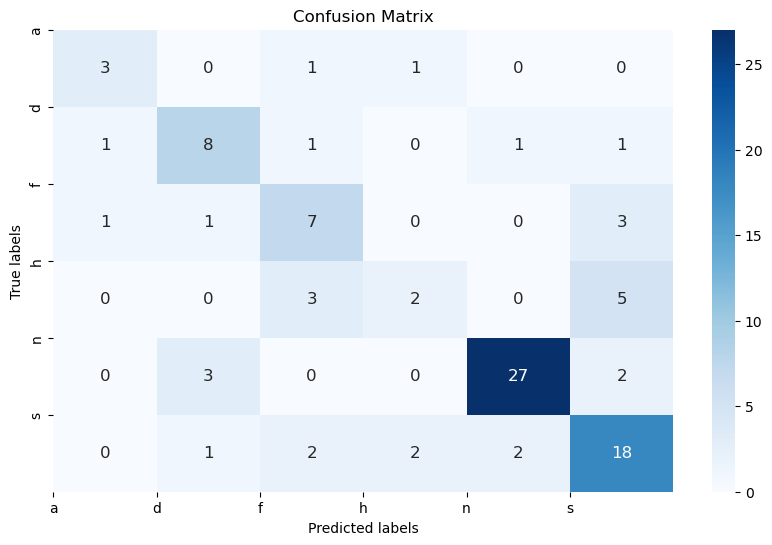

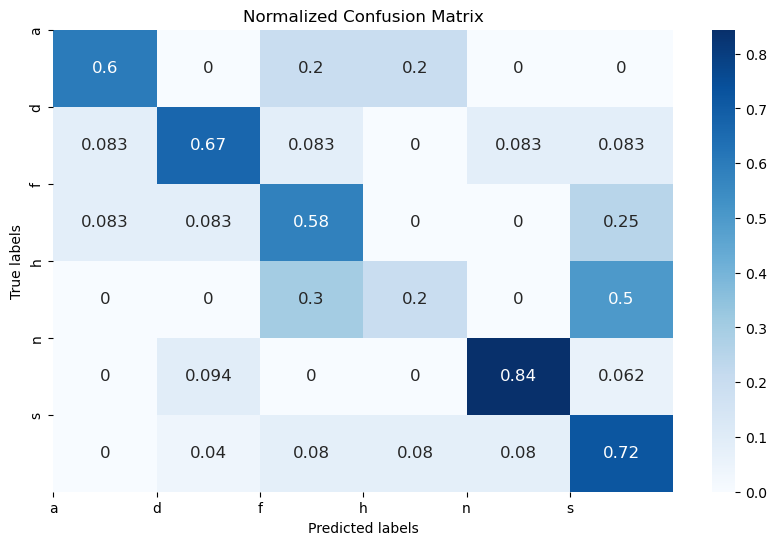

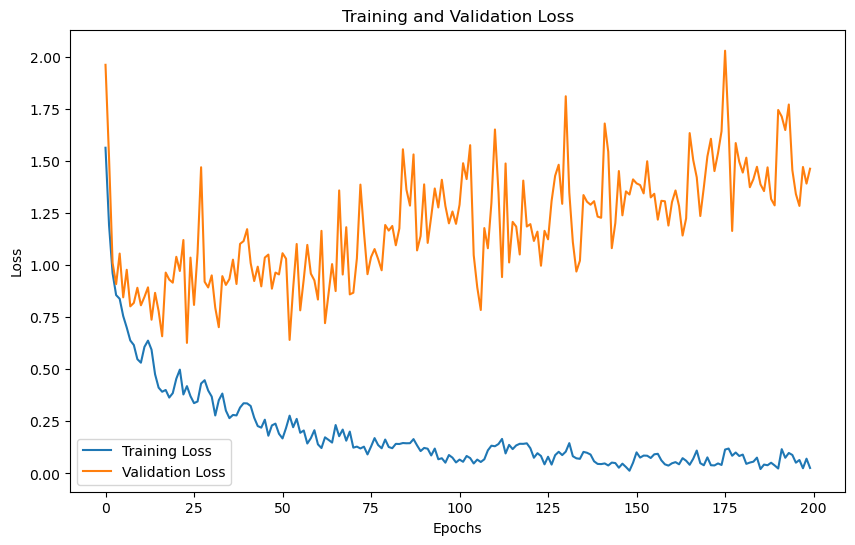

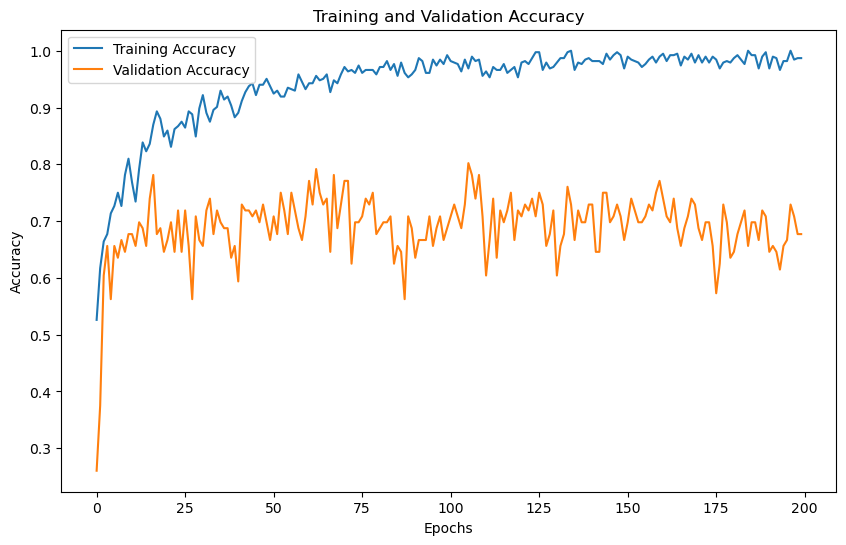

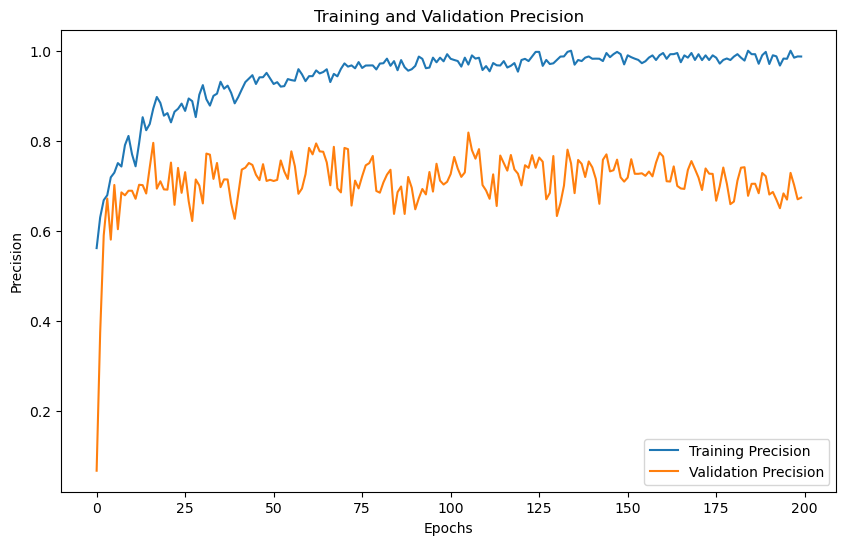

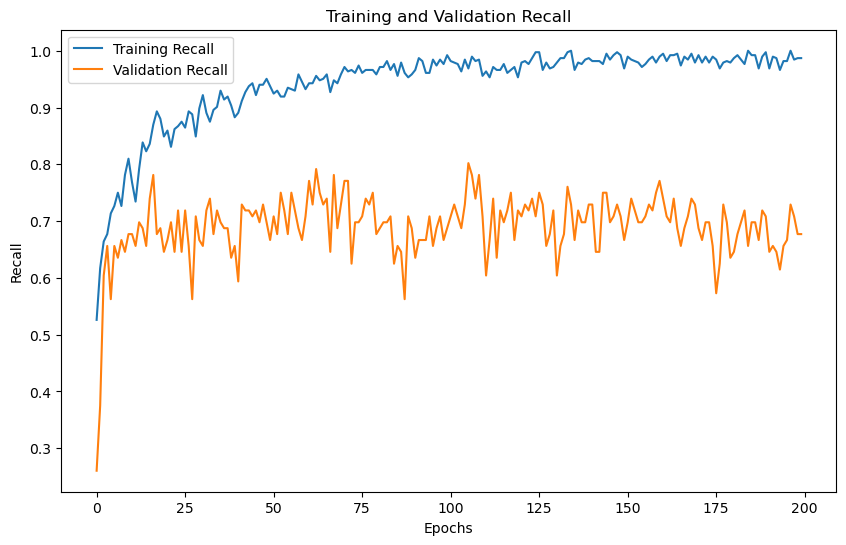

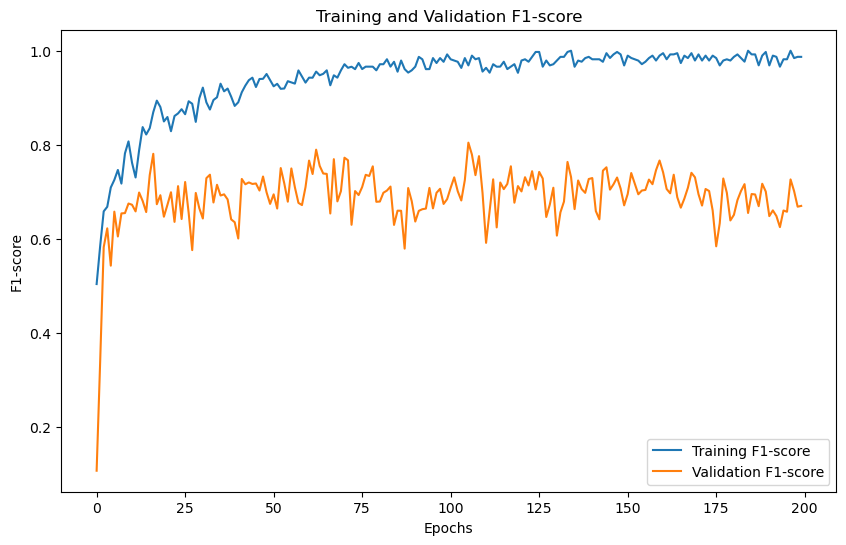

'Model Training and Evaluation Successfully completed'

In [23]:
train_model()

# SAVEE
# DWT 1
# N_MFCC 24
# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 24
No. of classes 6
Input size for wavelet level 1 = 48
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (480, 1, 48)
Y Shape : (480, 6)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.6071, Training Accuracy: 0.5573, Training Precision:0.5939,Training Recall:0.5573,Training F1-Score:0.5206
Validation Loss: 1.7065, Validation Accuracy: 0.2604, Validation Precision:0.1434,Validation Recall:0.2604,Validation F1-Score:0.1494
Epoch [2/200],
Training Loss: 1.1967, Training Accuracy: 0.5755, Training Precision:0.5688,Training Recall:0.5755,Training F1-Score:0.5715
Validation Loss: 1.7462, Validation Accuracy: 0.3333, Validation Precision:0.5352,Validation Recall:0.3333,Validation F1-Score:0.3155
Epoch [3/200],
Training Loss: 0.9486, Training Accuracy: 0.6458, Training Precision:0.6517,Training Recall:0.6458,Training F1-Score:0.6328
Val

Epoch [30/200],
Training Loss: 0.4988, Training Accuracy: 0.8359, Training Precision:0.8392,Training Recall:0.8359,Training F1-Score:0.8353
Validation Loss: 1.0384, Validation Accuracy: 0.6146, Validation Precision:0.6609,Validation Recall:0.6146,Validation F1-Score:0.6179
Epoch [31/200],
Training Loss: 0.3757, Training Accuracy: 0.8880, Training Precision:0.8929,Training Recall:0.8880,Training F1-Score:0.8883
Validation Loss: 0.9070, Validation Accuracy: 0.6562, Validation Precision:0.6850,Validation Recall:0.6562,Validation F1-Score:0.6532
Epoch [32/200],
Training Loss: 0.4159, Training Accuracy: 0.8802, Training Precision:0.8901,Training Recall:0.8802,Training F1-Score:0.8811
Validation Loss: 0.7490, Validation Accuracy: 0.6875, Validation Precision:0.7605,Validation Recall:0.6875,Validation F1-Score:0.6991
Epoch [33/200],
Training Loss: 0.4417, Training Accuracy: 0.8776, Training Precision:0.8897,Training Recall:0.8776,Training F1-Score:0.8764
Validation Loss: 0.7550, Validation Ac

Epoch [60/200],
Training Loss: 0.3224, Training Accuracy: 0.9245, Training Precision:0.9248,Training Recall:0.9245,Training F1-Score:0.9240
Validation Loss: 1.2433, Validation Accuracy: 0.6354, Validation Precision:0.6699,Validation Recall:0.6354,Validation F1-Score:0.6356
Epoch [61/200],
Training Loss: 0.3414, Training Accuracy: 0.8854, Training Precision:0.8866,Training Recall:0.8854,Training F1-Score:0.8840
Validation Loss: 1.0965, Validation Accuracy: 0.7500, Validation Precision:0.7757,Validation Recall:0.7500,Validation F1-Score:0.7433
Epoch [62/200],
Training Loss: 0.3302, Training Accuracy: 0.8854, Training Precision:0.8866,Training Recall:0.8854,Training F1-Score:0.8854
Validation Loss: 1.1623, Validation Accuracy: 0.6562, Validation Precision:0.6946,Validation Recall:0.6562,Validation F1-Score:0.6648
Epoch [63/200],
Training Loss: 0.3186, Training Accuracy: 0.9089, Training Precision:0.9108,Training Recall:0.9089,Training F1-Score:0.9082
Validation Loss: 1.0674, Validation Ac

Epoch [90/200],
Training Loss: 0.1974, Training Accuracy: 0.9766, Training Precision:0.9768,Training Recall:0.9766,Training F1-Score:0.9766
Validation Loss: 1.2350, Validation Accuracy: 0.7083, Validation Precision:0.7439,Validation Recall:0.7083,Validation F1-Score:0.7095
Epoch [91/200],
Training Loss: 0.1426, Training Accuracy: 0.9297, Training Precision:0.9326,Training Recall:0.9297,Training F1-Score:0.9299
Validation Loss: 1.2947, Validation Accuracy: 0.6667, Validation Precision:0.6907,Validation Recall:0.6667,Validation F1-Score:0.6729
Epoch [92/200],
Training Loss: 0.1405, Training Accuracy: 0.9505, Training Precision:0.9521,Training Recall:0.9505,Training F1-Score:0.9506
Validation Loss: 1.5983, Validation Accuracy: 0.6354, Validation Precision:0.6888,Validation Recall:0.6354,Validation F1-Score:0.6367
Epoch [93/200],
Training Loss: 0.1850, Training Accuracy: 0.9271, Training Precision:0.9297,Training Recall:0.9271,Training F1-Score:0.9262
Validation Loss: 1.1313, Validation Ac

Epoch [120/200],
Training Loss: 0.1414, Training Accuracy: 0.9479, Training Precision:0.9490,Training Recall:0.9479,Training F1-Score:0.9479
Validation Loss: 1.1764, Validation Accuracy: 0.7292, Validation Precision:0.7612,Validation Recall:0.7292,Validation F1-Score:0.7327
Epoch [121/200],
Training Loss: 0.1531, Training Accuracy: 0.9714, Training Precision:0.9720,Training Recall:0.9714,Training F1-Score:0.9713
Validation Loss: 1.2980, Validation Accuracy: 0.6979, Validation Precision:0.7222,Validation Recall:0.6979,Validation F1-Score:0.6958
Epoch [122/200],
Training Loss: 0.1465, Training Accuracy: 0.9583, Training Precision:0.9586,Training Recall:0.9583,Training F1-Score:0.9581
Validation Loss: 1.2040, Validation Accuracy: 0.7083, Validation Precision:0.7476,Validation Recall:0.7083,Validation F1-Score:0.7097
Epoch [123/200],
Training Loss: 0.1639, Training Accuracy: 0.9479, Training Precision:0.9490,Training Recall:0.9479,Training F1-Score:0.9481
Validation Loss: 1.1217, Validatio

Epoch [150/200],
Training Loss: 0.0872, Training Accuracy: 0.9714, Training Precision:0.9720,Training Recall:0.9714,Training F1-Score:0.9715
Validation Loss: 1.2867, Validation Accuracy: 0.7604, Validation Precision:0.7823,Validation Recall:0.7604,Validation F1-Score:0.7539
Epoch [151/200],
Training Loss: 0.0604, Training Accuracy: 0.9714, Training Precision:0.9730,Training Recall:0.9714,Training F1-Score:0.9715
Validation Loss: 1.3348, Validation Accuracy: 0.7396, Validation Precision:0.7649,Validation Recall:0.7396,Validation F1-Score:0.7405
Epoch [152/200],
Training Loss: 0.0267, Training Accuracy: 0.9844, Training Precision:0.9844,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 1.4993, Validation Accuracy: 0.7292, Validation Precision:0.7400,Validation Recall:0.7292,Validation F1-Score:0.7295
Epoch [153/200],
Training Loss: 0.1419, Training Accuracy: 0.9688, Training Precision:0.9696,Training Recall:0.9688,Training F1-Score:0.9688
Validation Loss: 1.3337, Validatio

Epoch [180/200],
Training Loss: 0.1125, Training Accuracy: 0.9609, Training Precision:0.9622,Training Recall:0.9609,Training F1-Score:0.9611
Validation Loss: 1.1705, Validation Accuracy: 0.7188, Validation Precision:0.7505,Validation Recall:0.7188,Validation F1-Score:0.7253
Epoch [181/200],
Training Loss: 0.1427, Training Accuracy: 0.9661, Training Precision:0.9664,Training Recall:0.9661,Training F1-Score:0.9661
Validation Loss: 1.5296, Validation Accuracy: 0.6771, Validation Precision:0.7351,Validation Recall:0.6771,Validation F1-Score:0.6901
Epoch [182/200],
Training Loss: 0.1046, Training Accuracy: 0.9609, Training Precision:0.9610,Training Recall:0.9609,Training F1-Score:0.9610
Validation Loss: 1.4686, Validation Accuracy: 0.6562, Validation Precision:0.6733,Validation Recall:0.6562,Validation F1-Score:0.6601
Epoch [183/200],
Training Loss: 0.0646, Training Accuracy: 0.9792, Training Precision:0.9797,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.3527, Validatio

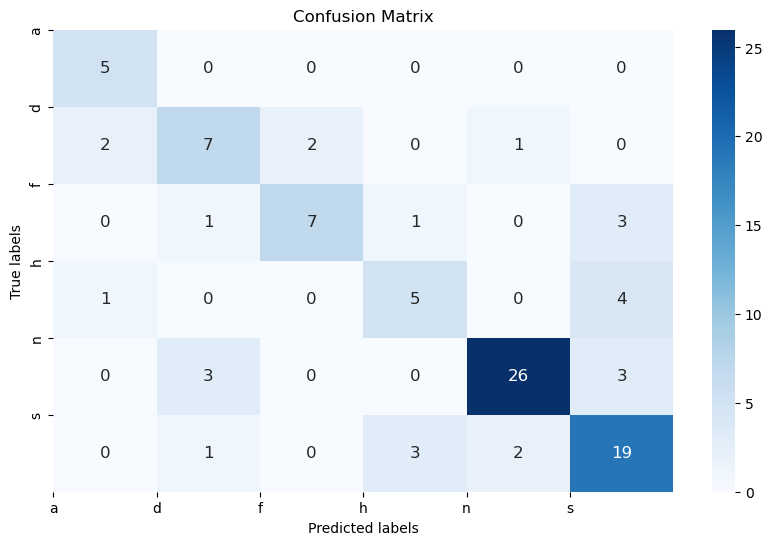

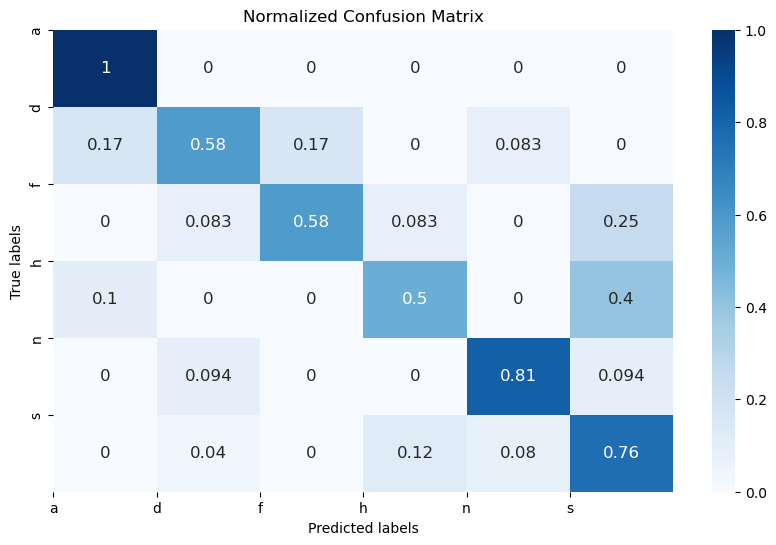

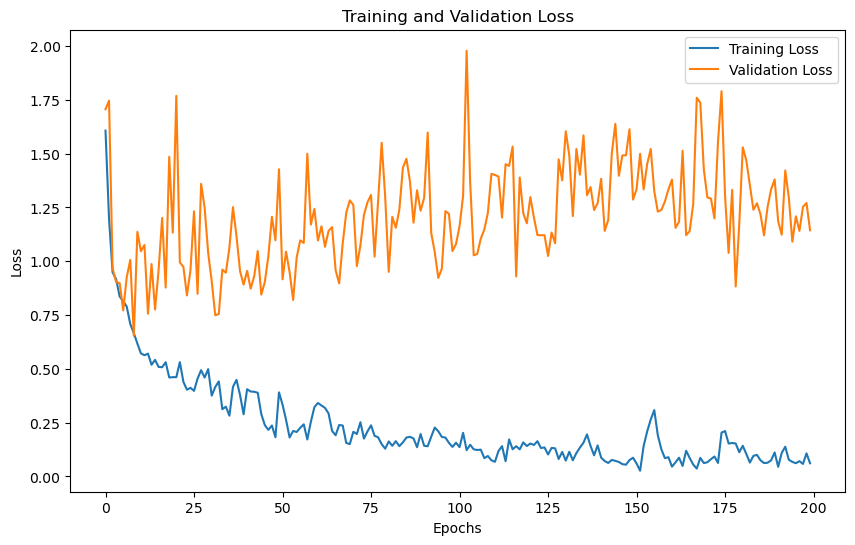

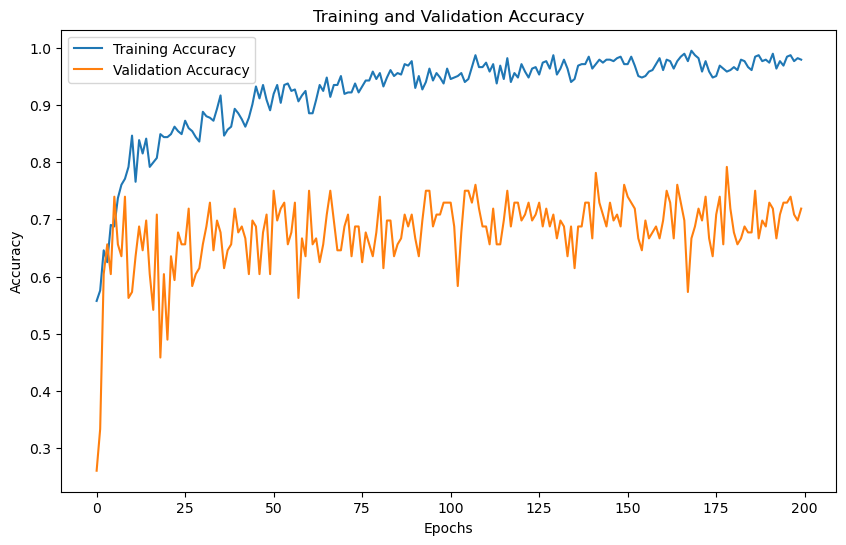

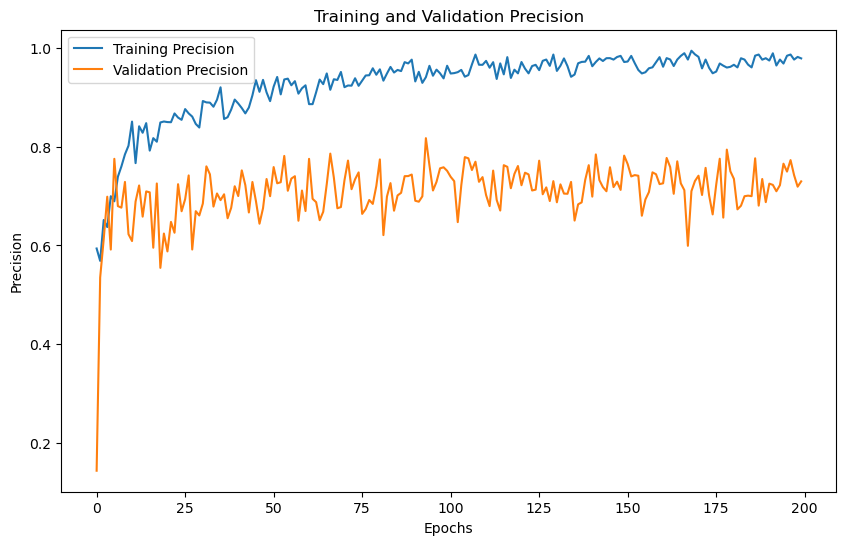

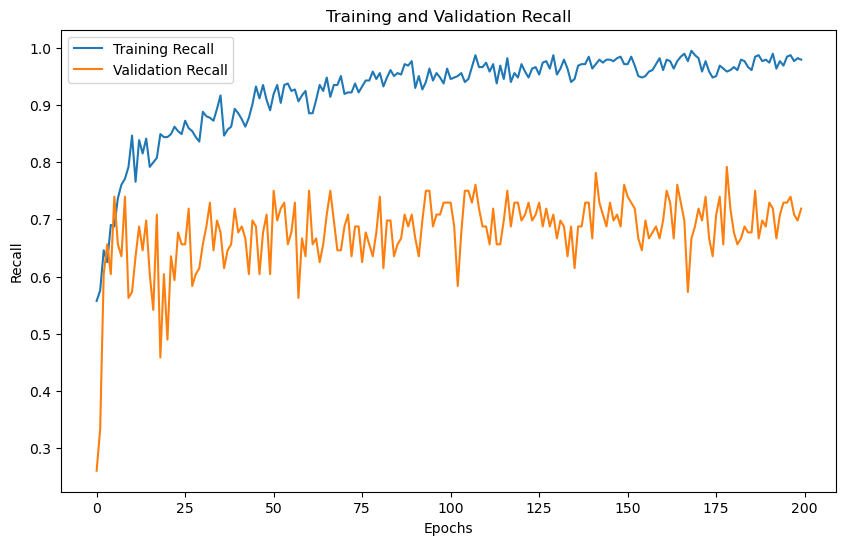

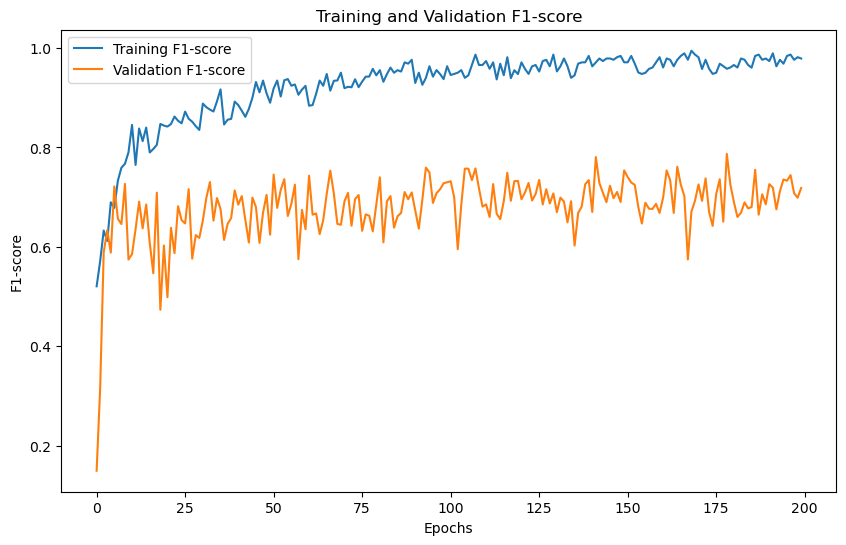

'Model Training and Evaluation Successfully completed'

In [11]:
train_model()

# SAVEE
# DWT 5
# N_MFCC 24
# 500 epoch

In [ ]:
train_model()

# RAVDESS
# DWT 1
# N_MFCC 24

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  1
Enter Number of MFCC coefficients : 24
No. of classes 8
Input size for wavelet level 1 = 48
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (1440, 1, 48)
Y Shape : (1440, 8)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.8948, Training Accuracy: 0.3524, Training Precision:0.4095,Training Recall:0.3524,Training F1-Score:0.3057
Validation Loss: 1.6915, Validation Accuracy: 0.3646, Validation Precision:0.3060,Validation Recall:0.3646,Validation F1-Score:0.3129
Epoch [2/200],
Training Loss: 1.7352, Training Accuracy: 0.3698, Training Precision:0.3604,Training Recall:0.3698,Training F1-Score:0.3390
Validation Loss: 1.5864, Validation Accuracy: 0.4201, Validation Precision:0.3954,Validation Recall:0.4201,Validation F1-Score:0.3854
Epoch [3/200],
Training Loss: 1.6787, Training Accuracy: 0.3915, Training Precision:0.3896,Training Recall:0.3915,Training F1-Score:0.3553

Epoch [30/200],
Training Loss: 0.9755, Training Accuracy: 0.6589, Training Precision:0.6602,Training Recall:0.6589,Training F1-Score:0.6539
Validation Loss: 1.4608, Validation Accuracy: 0.5278, Validation Precision:0.5395,Validation Recall:0.5278,Validation F1-Score:0.5116
Epoch [31/200],
Training Loss: 1.0075, Training Accuracy: 0.6719, Training Precision:0.6799,Training Recall:0.6719,Training F1-Score:0.6704
Validation Loss: 1.3342, Validation Accuracy: 0.5104, Validation Precision:0.5108,Validation Recall:0.5104,Validation F1-Score:0.5043
Epoch [32/200],
Training Loss: 0.9304, Training Accuracy: 0.6788, Training Precision:0.6807,Training Recall:0.6788,Training F1-Score:0.6778
Validation Loss: 1.4451, Validation Accuracy: 0.4722, Validation Precision:0.4655,Validation Recall:0.4722,Validation F1-Score:0.4644
Epoch [33/200],
Training Loss: 0.9498, Training Accuracy: 0.6866, Training Precision:0.6945,Training Recall:0.6866,Training F1-Score:0.6862
Validation Loss: 1.5542, Validation Ac

Epoch [60/200],
Training Loss: 0.4959, Training Accuracy: 0.8637, Training Precision:0.8684,Training Recall:0.8637,Training F1-Score:0.8640
Validation Loss: 1.3937, Validation Accuracy: 0.5694, Validation Precision:0.5619,Validation Recall:0.5694,Validation F1-Score:0.5597
Epoch [61/200],
Training Loss: 0.4183, Training Accuracy: 0.8490, Training Precision:0.8559,Training Recall:0.8490,Training F1-Score:0.8494
Validation Loss: 1.4980, Validation Accuracy: 0.5312, Validation Precision:0.5792,Validation Recall:0.5312,Validation F1-Score:0.5379
Epoch [62/200],
Training Loss: 0.4212, Training Accuracy: 0.8811, Training Precision:0.8821,Training Recall:0.8811,Training F1-Score:0.8803
Validation Loss: 1.4168, Validation Accuracy: 0.5625, Validation Precision:0.5703,Validation Recall:0.5625,Validation F1-Score:0.5641
Epoch [63/200],
Training Loss: 0.4729, Training Accuracy: 0.8689, Training Precision:0.8744,Training Recall:0.8689,Training F1-Score:0.8700
Validation Loss: 1.4770, Validation Ac

Epoch [90/200],
Training Loss: 0.2764, Training Accuracy: 0.9245, Training Precision:0.9258,Training Recall:0.9245,Training F1-Score:0.9245
Validation Loss: 1.5720, Validation Accuracy: 0.5833, Validation Precision:0.5891,Validation Recall:0.5833,Validation F1-Score:0.5816
Epoch [91/200],
Training Loss: 0.2560, Training Accuracy: 0.9245, Training Precision:0.9270,Training Recall:0.9245,Training F1-Score:0.9244
Validation Loss: 1.6198, Validation Accuracy: 0.5625, Validation Precision:0.5591,Validation Recall:0.5625,Validation F1-Score:0.5585
Epoch [92/200],
Training Loss: 0.2023, Training Accuracy: 0.9566, Training Precision:0.9565,Training Recall:0.9566,Training F1-Score:0.9564
Validation Loss: 1.6313, Validation Accuracy: 0.6146, Validation Precision:0.6246,Validation Recall:0.6146,Validation F1-Score:0.6125
Epoch [93/200],
Training Loss: 0.2326, Training Accuracy: 0.9392, Training Precision:0.9404,Training Recall:0.9392,Training F1-Score:0.9393
Validation Loss: 1.5852, Validation Ac

Epoch [120/200],
Training Loss: 0.1000, Training Accuracy: 0.9913, Training Precision:0.9915,Training Recall:0.9913,Training F1-Score:0.9913
Validation Loss: 1.6763, Validation Accuracy: 0.6319, Validation Precision:0.6318,Validation Recall:0.6319,Validation F1-Score:0.6309
Epoch [121/200],
Training Loss: 0.0693, Training Accuracy: 0.9826, Training Precision:0.9832,Training Recall:0.9826,Training F1-Score:0.9827
Validation Loss: 1.6447, Validation Accuracy: 0.6319, Validation Precision:0.6429,Validation Recall:0.6319,Validation F1-Score:0.6339
Epoch [122/200],
Training Loss: 0.0734, Training Accuracy: 0.9757, Training Precision:0.9760,Training Recall:0.9757,Training F1-Score:0.9757
Validation Loss: 1.6952, Validation Accuracy: 0.6354, Validation Precision:0.6337,Validation Recall:0.6354,Validation F1-Score:0.6331
Epoch [123/200],
Training Loss: 0.0939, Training Accuracy: 0.9809, Training Precision:0.9812,Training Recall:0.9809,Training F1-Score:0.9809
Validation Loss: 1.6427, Validatio

Epoch [150/200],
Training Loss: 0.1317, Training Accuracy: 0.9722, Training Precision:0.9725,Training Recall:0.9722,Training F1-Score:0.9723
Validation Loss: 1.7974, Validation Accuracy: 0.6042, Validation Precision:0.6084,Validation Recall:0.6042,Validation F1-Score:0.6050
Epoch [151/200],
Training Loss: 0.1113, Training Accuracy: 0.9661, Training Precision:0.9666,Training Recall:0.9661,Training F1-Score:0.9662
Validation Loss: 1.7353, Validation Accuracy: 0.5868, Validation Precision:0.5837,Validation Recall:0.5868,Validation F1-Score:0.5841
Epoch [152/200],
Training Loss: 0.1016, Training Accuracy: 0.9792, Training Precision:0.9801,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.7837, Validation Accuracy: 0.5972, Validation Precision:0.6069,Validation Recall:0.5972,Validation F1-Score:0.5973
Epoch [153/200],
Training Loss: 0.1075, Training Accuracy: 0.9809, Training Precision:0.9811,Training Recall:0.9809,Training F1-Score:0.9809
Validation Loss: 1.9816, Validatio

Epoch [180/200],
Training Loss: 0.0784, Training Accuracy: 0.9809, Training Precision:0.9811,Training Recall:0.9809,Training F1-Score:0.9809
Validation Loss: 1.7967, Validation Accuracy: 0.6319, Validation Precision:0.6340,Validation Recall:0.6319,Validation F1-Score:0.6317
Epoch [181/200],
Training Loss: 0.0772, Training Accuracy: 0.9731, Training Precision:0.9735,Training Recall:0.9731,Training F1-Score:0.9732
Validation Loss: 1.7435, Validation Accuracy: 0.6493, Validation Precision:0.6480,Validation Recall:0.6493,Validation F1-Score:0.6441
Epoch [182/200],
Training Loss: 0.0686, Training Accuracy: 0.9852, Training Precision:0.9853,Training Recall:0.9852,Training F1-Score:0.9853
Validation Loss: 1.7458, Validation Accuracy: 0.6354, Validation Precision:0.6363,Validation Recall:0.6354,Validation F1-Score:0.6347
Epoch [183/200],
Training Loss: 0.0689, Training Accuracy: 0.9818, Training Precision:0.9820,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 1.7901, Validatio

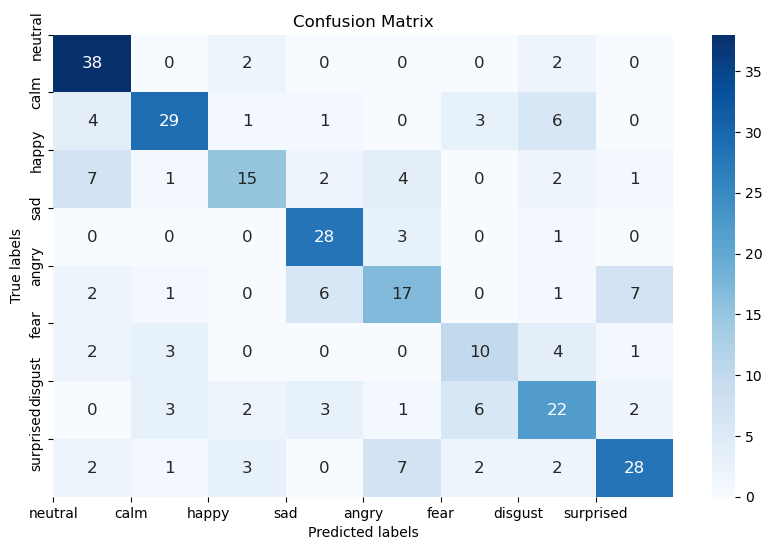

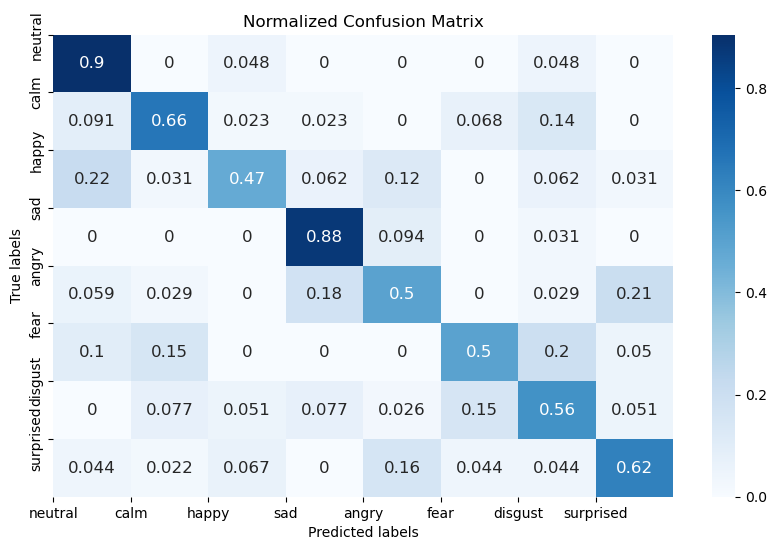

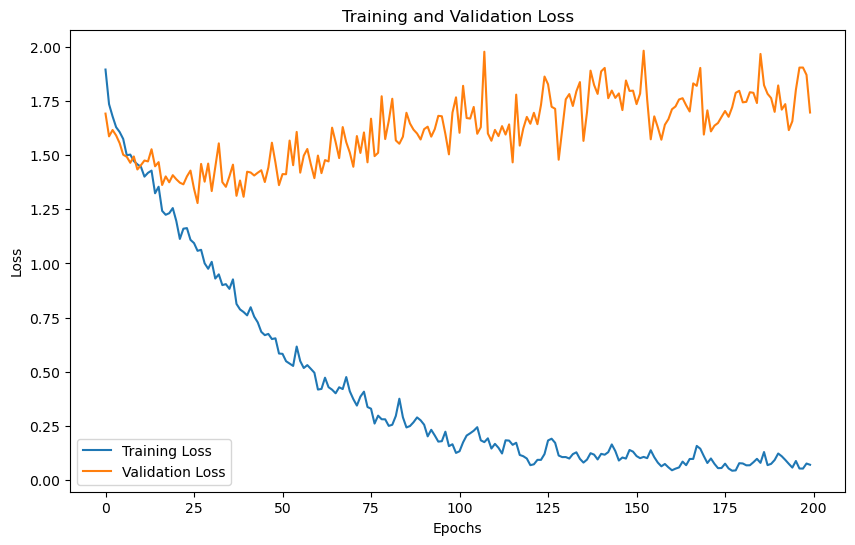

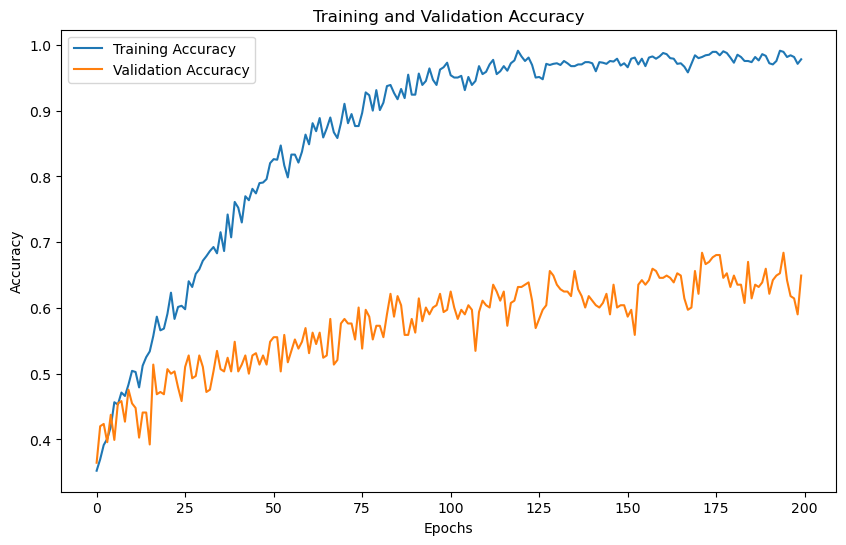

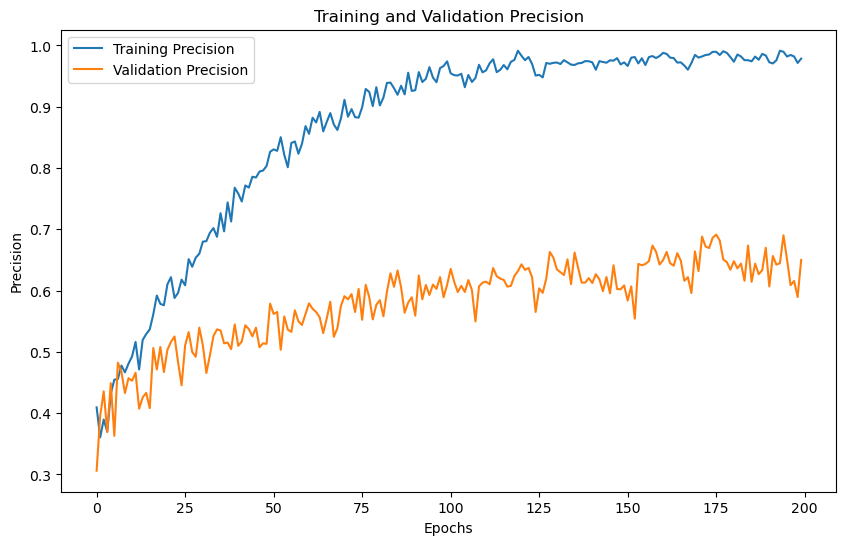

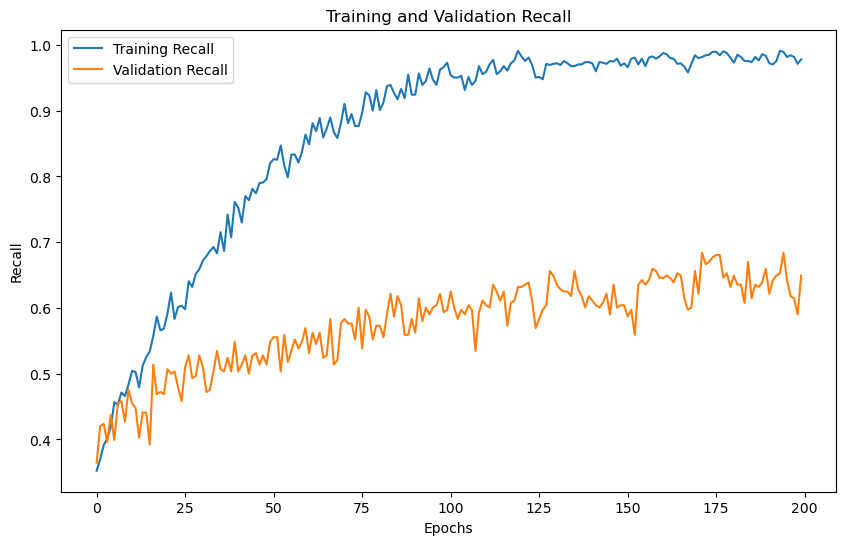

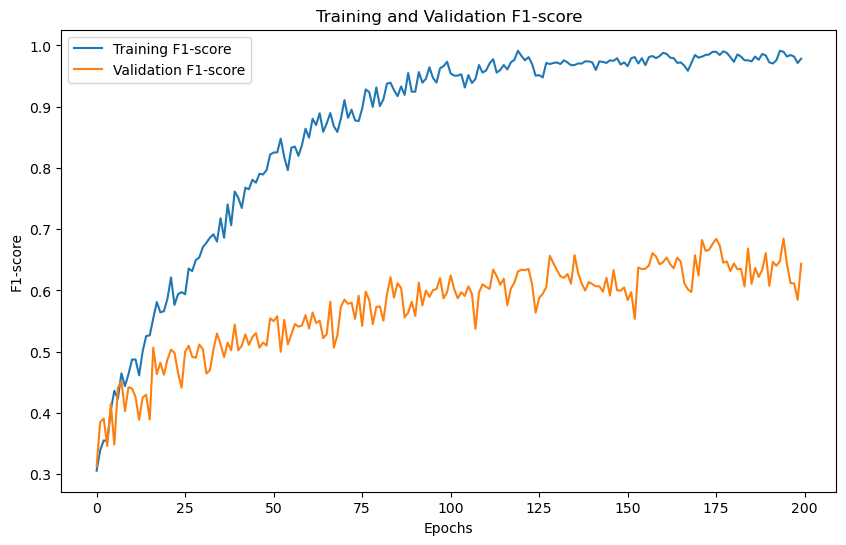

'Model Training and Evaluation Successfully completed'

In [13]:
train_model()

# RAVDESS
# DWT 2
# N_MFCC 24

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  2
Enter Number of MFCC coefficients : 32
No. of classes 8
Input size for wavelet level 2 = 96
Training with DWT level: 2
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (1440, 1, 96)
Y Shape : (1440, 8)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.8799, Training Accuracy: 0.3637, Training Precision:0.3665,Training Recall:0.3637,Training F1-Score:0.3458
Validation Loss: 1.6840, Validation Accuracy: 0.3958, Validation Precision:0.4038,Validation Recall:0.3958,Validation F1-Score:0.3779
Epoch [2/200],
Training Loss: 1.6725, Training Accuracy: 0.4141, Training Precision:0.4151,Training Recall:0.4141,Training F1-Score:0.3918
Validation Loss: 1.6291, Validation Accuracy: 0.3715, Validation Precision:0.3290,Validation Recall:0.3715,Validation F1-Score:0.3396
Epoch [3/200],
Training Loss: 1.6029, Training Accuracy: 0.4688, Training Precision:0.4793,Training Recall:0.4688,Training F1-Score:0.4617

Epoch [30/200],
Training Loss: 0.3236, Training Accuracy: 0.9054, Training Precision:0.9064,Training Recall:0.9054,Training F1-Score:0.9056
Validation Loss: 1.7806, Validation Accuracy: 0.5312, Validation Precision:0.5489,Validation Recall:0.5312,Validation F1-Score:0.5266
Epoch [31/200],
Training Loss: 0.3026, Training Accuracy: 0.9097, Training Precision:0.9127,Training Recall:0.9097,Training F1-Score:0.9094
Validation Loss: 1.6362, Validation Accuracy: 0.5521, Validation Precision:0.5541,Validation Recall:0.5521,Validation F1-Score:0.5394
Epoch [32/200],
Training Loss: 0.2931, Training Accuracy: 0.9089, Training Precision:0.9092,Training Recall:0.9089,Training F1-Score:0.9086
Validation Loss: 1.6825, Validation Accuracy: 0.5278, Validation Precision:0.5458,Validation Recall:0.5278,Validation F1-Score:0.5294
Epoch [33/200],
Training Loss: 0.3297, Training Accuracy: 0.9097, Training Precision:0.9128,Training Recall:0.9097,Training F1-Score:0.9099
Validation Loss: 1.6082, Validation Ac

Epoch [60/200],
Training Loss: 0.1743, Training Accuracy: 0.9731, Training Precision:0.9739,Training Recall:0.9731,Training F1-Score:0.9731
Validation Loss: 1.8233, Validation Accuracy: 0.5486, Validation Precision:0.5740,Validation Recall:0.5486,Validation F1-Score:0.5530
Epoch [61/200],
Training Loss: 0.0939, Training Accuracy: 0.9852, Training Precision:0.9853,Training Recall:0.9852,Training F1-Score:0.9853
Validation Loss: 2.0055, Validation Accuracy: 0.5417, Validation Precision:0.5428,Validation Recall:0.5417,Validation F1-Score:0.5250
Epoch [62/200],
Training Loss: 0.0526, Training Accuracy: 0.9835, Training Precision:0.9838,Training Recall:0.9835,Training F1-Score:0.9835
Validation Loss: 1.7434, Validation Accuracy: 0.5938, Validation Precision:0.6030,Validation Recall:0.5938,Validation F1-Score:0.5964
Epoch [63/200],
Training Loss: 0.0776, Training Accuracy: 0.9826, Training Precision:0.9830,Training Recall:0.9826,Training F1-Score:0.9827
Validation Loss: 1.9994, Validation Ac

Epoch [90/200],
Training Loss: 0.0516, Training Accuracy: 0.9939, Training Precision:0.9940,Training Recall:0.9939,Training F1-Score:0.9939
Validation Loss: 1.8961, Validation Accuracy: 0.5729, Validation Precision:0.5712,Validation Recall:0.5729,Validation F1-Score:0.5712
Epoch [91/200],
Training Loss: 0.0340, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.8221, Validation Accuracy: 0.6111, Validation Precision:0.6125,Validation Recall:0.6111,Validation F1-Score:0.6058
Epoch [92/200],
Training Loss: 0.0281, Training Accuracy: 0.9948, Training Precision:0.9948,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 2.0847, Validation Accuracy: 0.5590, Validation Precision:0.5771,Validation Recall:0.5590,Validation F1-Score:0.5489
Epoch [93/200],
Training Loss: 0.0270, Training Accuracy: 0.9957, Training Precision:0.9957,Training Recall:0.9957,Training F1-Score:0.9957
Validation Loss: 2.0134, Validation Ac

Epoch [120/200],
Training Loss: 0.0289, Training Accuracy: 0.9965, Training Precision:0.9966,Training Recall:0.9965,Training F1-Score:0.9965
Validation Loss: 2.1817, Validation Accuracy: 0.5625, Validation Precision:0.5784,Validation Recall:0.5625,Validation F1-Score:0.5651
Epoch [121/200],
Training Loss: 0.0232, Training Accuracy: 0.9957, Training Precision:0.9957,Training Recall:0.9957,Training F1-Score:0.9957
Validation Loss: 2.1833, Validation Accuracy: 0.5833, Validation Precision:0.6061,Validation Recall:0.5833,Validation F1-Score:0.5779
Epoch [122/200],
Training Loss: 0.0189, Training Accuracy: 0.9965, Training Precision:0.9966,Training Recall:0.9965,Training F1-Score:0.9965
Validation Loss: 2.1767, Validation Accuracy: 0.5660, Validation Precision:0.5628,Validation Recall:0.5660,Validation F1-Score:0.5582
Epoch [123/200],
Training Loss: 0.0377, Training Accuracy: 0.9931, Training Precision:0.9932,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 2.3250, Validatio

Epoch [150/200],
Training Loss: 0.0372, Training Accuracy: 0.9887, Training Precision:0.9888,Training Recall:0.9887,Training F1-Score:0.9887
Validation Loss: 2.0939, Validation Accuracy: 0.5764, Validation Precision:0.5849,Validation Recall:0.5764,Validation F1-Score:0.5718
Epoch [151/200],
Training Loss: 0.0376, Training Accuracy: 0.9887, Training Precision:0.9889,Training Recall:0.9887,Training F1-Score:0.9887
Validation Loss: 2.1686, Validation Accuracy: 0.5382, Validation Precision:0.5521,Validation Recall:0.5382,Validation F1-Score:0.5417
Epoch [152/200],
Training Loss: 0.0592, Training Accuracy: 0.9931, Training Precision:0.9931,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 2.1777, Validation Accuracy: 0.5417, Validation Precision:0.5492,Validation Recall:0.5417,Validation F1-Score:0.5411
Epoch [153/200],
Training Loss: 0.0422, Training Accuracy: 0.9887, Training Precision:0.9888,Training Recall:0.9887,Training F1-Score:0.9887
Validation Loss: 2.0465, Validatio

Epoch [180/200],
Training Loss: 0.0119, Training Accuracy: 0.9983, Training Precision:0.9983,Training Recall:0.9983,Training F1-Score:0.9983
Validation Loss: 2.3047, Validation Accuracy: 0.5729, Validation Precision:0.5716,Validation Recall:0.5729,Validation F1-Score:0.5677
Epoch [181/200],
Training Loss: 0.0073, Training Accuracy: 0.9965, Training Precision:0.9965,Training Recall:0.9965,Training F1-Score:0.9965
Validation Loss: 2.2616, Validation Accuracy: 0.5764, Validation Precision:0.5762,Validation Recall:0.5764,Validation F1-Score:0.5718
Epoch [182/200],
Training Loss: 0.0059, Training Accuracy: 0.9983, Training Precision:0.9983,Training Recall:0.9983,Training F1-Score:0.9983
Validation Loss: 2.2235, Validation Accuracy: 0.5625, Validation Precision:0.5646,Validation Recall:0.5625,Validation F1-Score:0.5586
Epoch [183/200],
Training Loss: 0.0106, Training Accuracy: 0.9983, Training Precision:0.9983,Training Recall:0.9983,Training F1-Score:0.9983
Validation Loss: 2.1911, Validatio

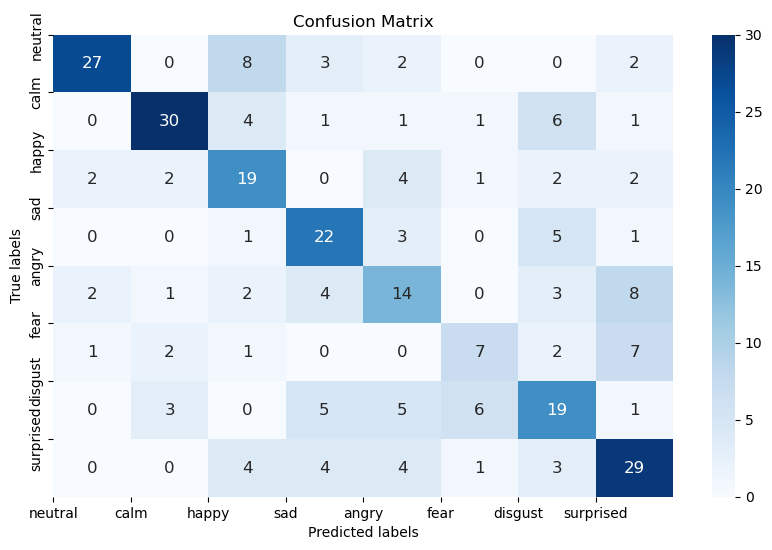

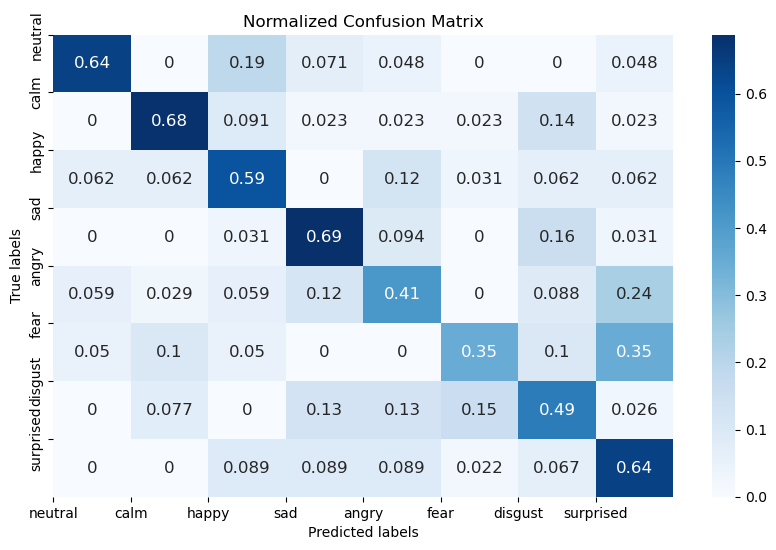

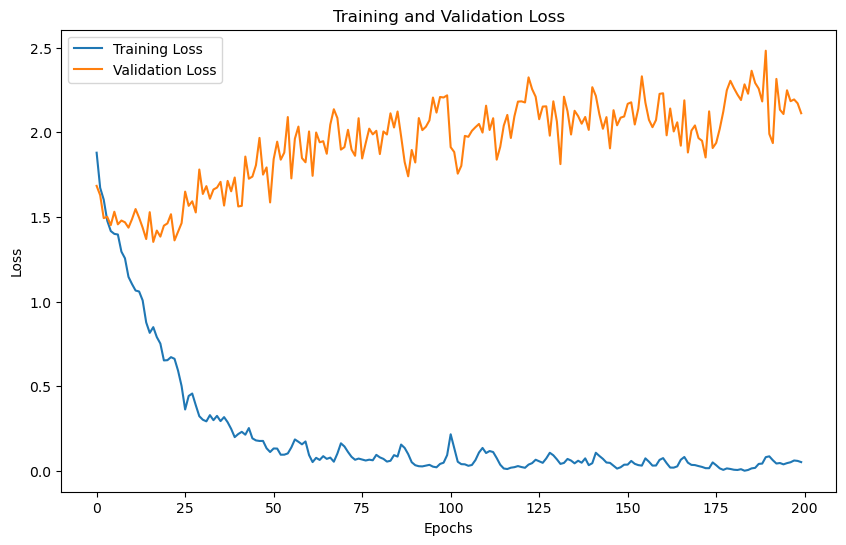

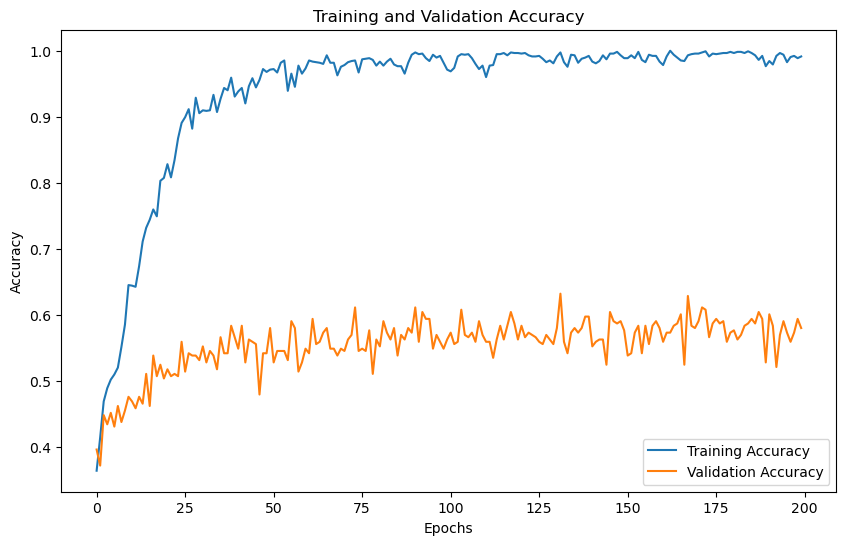

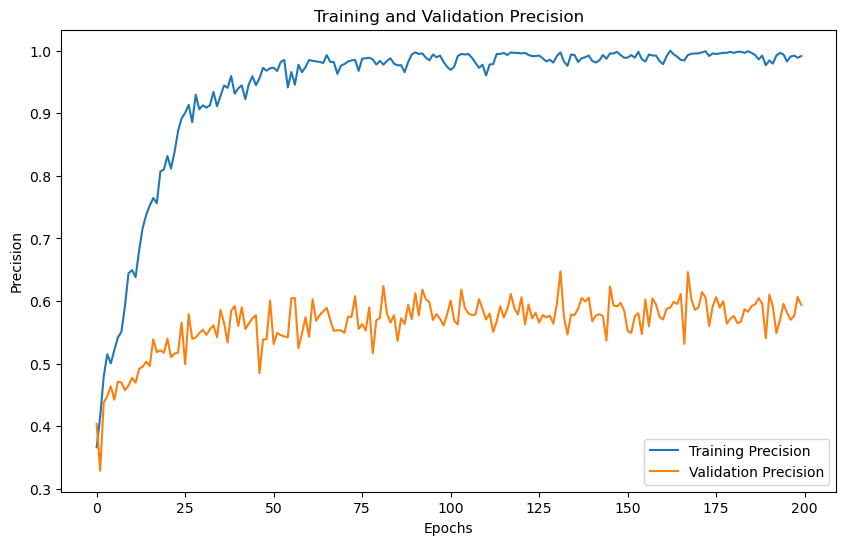

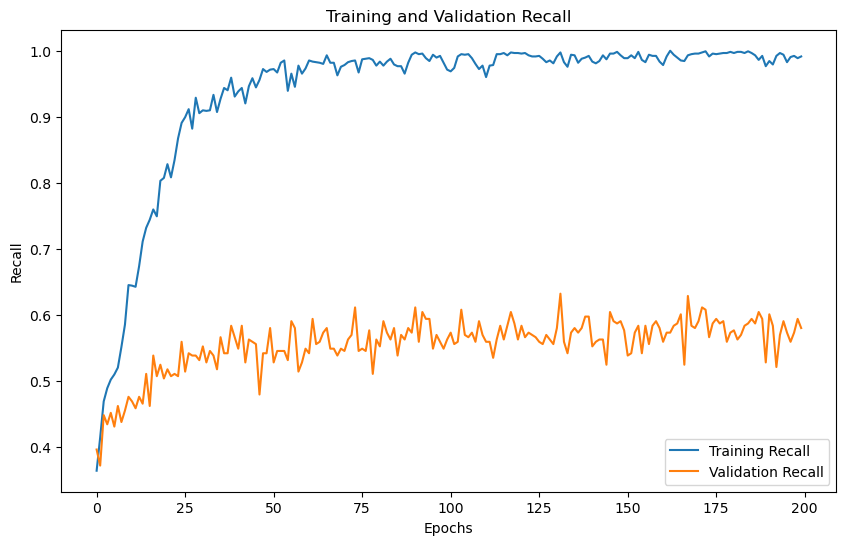

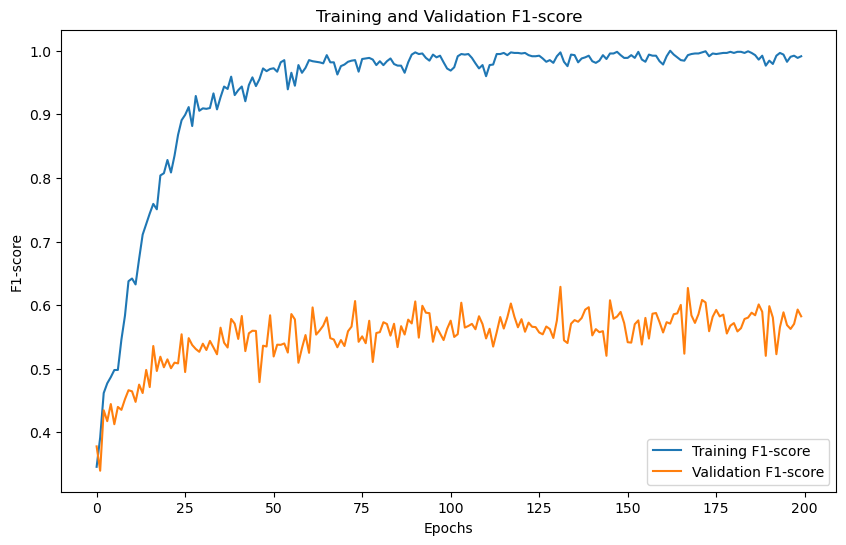

'Model Training and Evaluation Successfully completed'

In [25]:
train_model()

# TESS
# DWT 1
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  1
Enter Number of MFCC coefficients : 32
No. of classes 7
Input size for wavelet level 1 = 64
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (2800, 1, 64)
Y Shape : (2800, 7)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 0.5264, Training Accuracy: 0.9558, Training Precision:0.9562,Training Recall:0.9558,Training F1-Score:0.9558
Validation Loss: 0.1358, Validation Accuracy: 0.9679, Validation Precision:0.9696,Validation Recall:0.9679,Validation F1-Score:0.9681
Epoch [2/200],
Training Loss: 0.2245, Training Accuracy: 0.9634, Training Precision:0.9636,Training Recall:0.9634,Training F1-Score:0.9631
Validation Loss: 0.1233, Validation Accuracy: 0.9661, Validation Precision:0.9686,Validation Recall:0.9661,Validation F1-Score:0.9656
Epoch [3/200],
Training Loss: 0.1609, Training Accuracy: 0.9518, Training Precision:0.9528,Training Recall:0.9518,Training F1-Score:0.9513
Va

Epoch [30/200],
Training Loss: 0.0236, Training Accuracy: 0.9938, Training Precision:0.9938,Training Recall:0.9938,Training F1-Score:0.9937
Validation Loss: 0.0845, Validation Accuracy: 0.9750, Validation Precision:0.9756,Validation Recall:0.9750,Validation F1-Score:0.9750
Epoch [31/200],
Training Loss: 0.0264, Training Accuracy: 0.9871, Training Precision:0.9874,Training Recall:0.9871,Training F1-Score:0.9870
Validation Loss: 0.0525, Validation Accuracy: 0.9821, Validation Precision:0.9825,Validation Recall:0.9821,Validation F1-Score:0.9821
Epoch [32/200],
Training Loss: 0.0302, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 0.0264, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [33/200],
Training Loss: 0.0355, Training Accuracy: 0.9938, Training Precision:0.9939,Training Recall:0.9938,Training F1-Score:0.9937
Validation Loss: 0.0453, Validation Ac

Epoch [60/200],
Training Loss: 0.0128, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 0.0390, Validation Accuracy: 0.9875, Validation Precision:0.9878,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [61/200],
Training Loss: 0.0283, Training Accuracy: 0.9795, Training Precision:0.9810,Training Recall:0.9795,Training F1-Score:0.9794
Validation Loss: 0.0744, Validation Accuracy: 0.9804, Validation Precision:0.9814,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [62/200],
Training Loss: 0.0278, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 0.0498, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [63/200],
Training Loss: 0.0230, Training Accuracy: 0.9955, Training Precision:0.9955,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 0.0398, Validation Ac

Epoch [90/200],
Training Loss: 0.0070, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 0.0405, Validation Accuracy: 0.9875, Validation Precision:0.9878,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [91/200],
Training Loss: 0.0158, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 0.0349, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [92/200],
Training Loss: 0.0228, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 0.0466, Validation Accuracy: 0.9821, Validation Precision:0.9826,Validation Recall:0.9821,Validation F1-Score:0.9822
Epoch [93/200],
Training Loss: 0.0370, Training Accuracy: 0.9888, Training Precision:0.9892,Training Recall:0.9888,Training F1-Score:0.9889
Validation Loss: 0.0939, Validation Ac

Epoch [120/200],
Training Loss: 0.0110, Training Accuracy: 0.9960, Training Precision:0.9961,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 0.0381, Validation Accuracy: 0.9929, Validation Precision:0.9930,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [121/200],
Training Loss: 0.0252, Training Accuracy: 0.9893, Training Precision:0.9895,Training Recall:0.9893,Training F1-Score:0.9893
Validation Loss: 0.0863, Validation Accuracy: 0.9768, Validation Precision:0.9778,Validation Recall:0.9768,Validation F1-Score:0.9769
Epoch [122/200],
Training Loss: 0.0231, Training Accuracy: 0.9951, Training Precision:0.9952,Training Recall:0.9951,Training F1-Score:0.9951
Validation Loss: 0.0452, Validation Accuracy: 0.9911, Validation Precision:0.9911,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [123/200],
Training Loss: 0.0144, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 0.0497, Validatio

Epoch [150/200],
Training Loss: 0.0323, Training Accuracy: 0.9942, Training Precision:0.9943,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 0.0373, Validation Accuracy: 0.9911, Validation Precision:0.9914,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [151/200],
Training Loss: 0.0202, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 0.0404, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [152/200],
Training Loss: 0.0317, Training Accuracy: 0.9920, Training Precision:0.9923,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 0.0570, Validation Accuracy: 0.9875, Validation Precision:0.9882,Validation Recall:0.9875,Validation F1-Score:0.9876
Epoch [153/200],
Training Loss: 0.0361, Training Accuracy: 0.9951, Training Precision:0.9952,Training Recall:0.9951,Training F1-Score:0.9951
Validation Loss: 0.0552, Validatio

Epoch [180/200],
Training Loss: 0.0041, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0376, Validation Accuracy: 0.9911, Validation Precision:0.9914,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [181/200],
Training Loss: 0.0029, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0363, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [182/200],
Training Loss: 0.0005, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0308, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [183/200],
Training Loss: 0.0007, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0239, Validatio

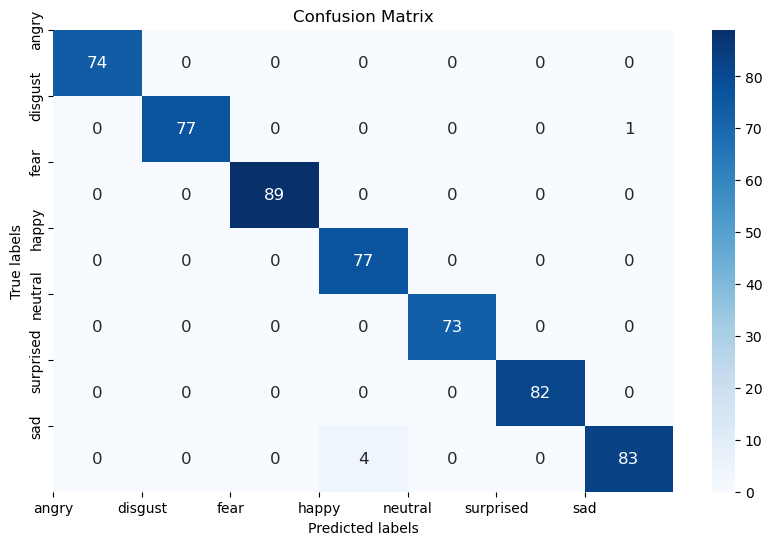

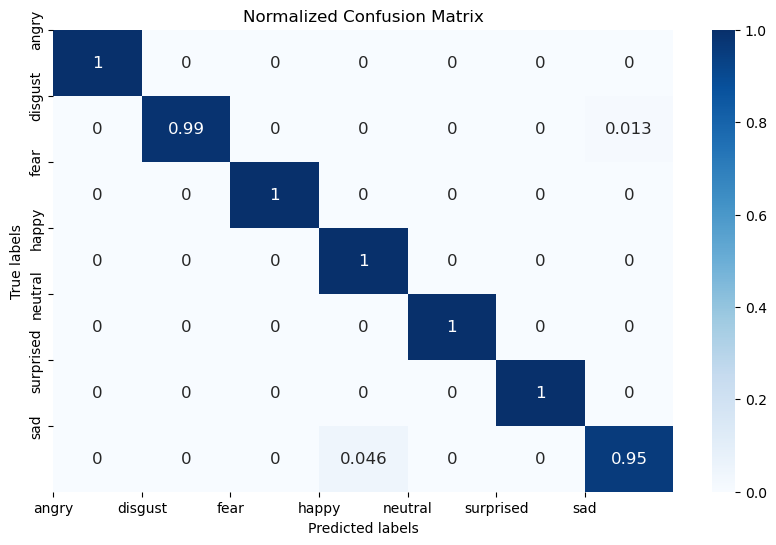

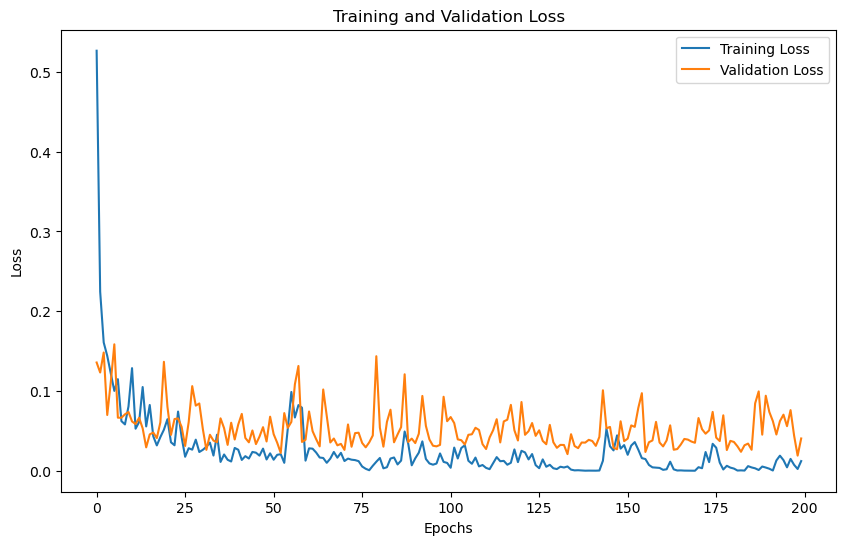

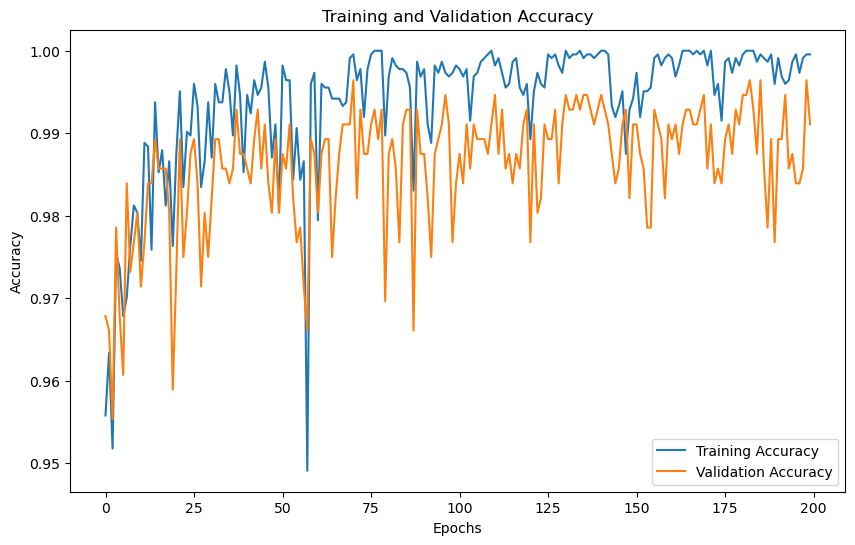

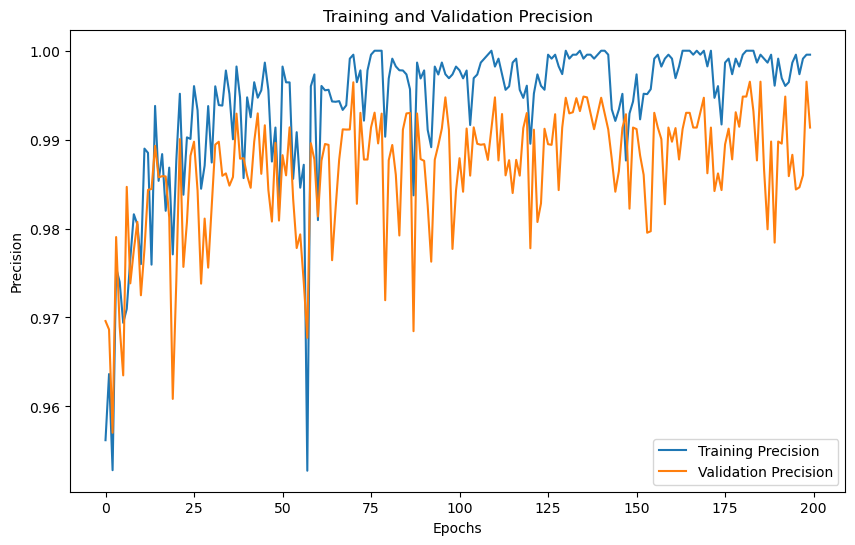

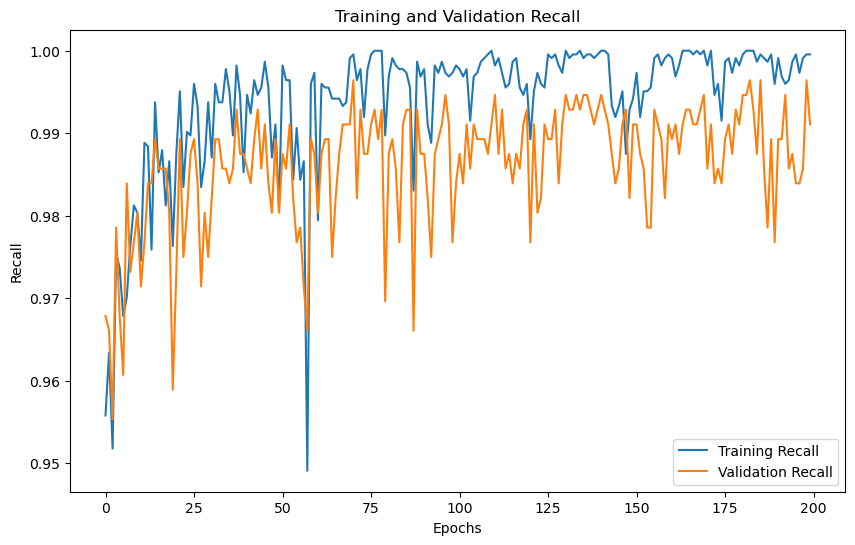

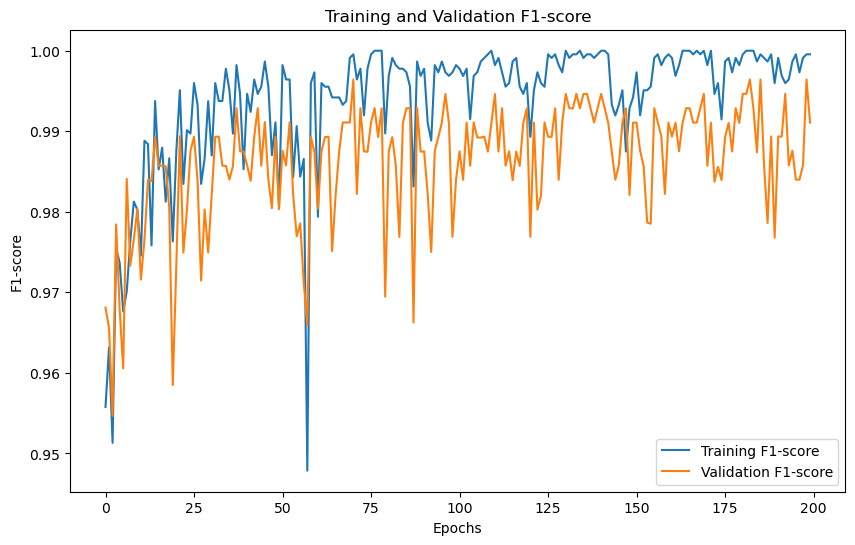

'Model Training and Evaluation Successfully completed'

In [14]:
train_model()

# TESS
# DWT 3
# N_MFCC 32

In [ ]:
train_model()

# TESS
# DWT 4
# N_MFCC 40

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  4
Enter Number of MFCC coefficients : 40
No. of classes 7
Input size for wavelet level 4 = 200
Training with DWT level: 4
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (2800, 1, 200)
Y Shape : (2800, 7)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 0.5249, Training Accuracy: 0.9313, Training Precision:0.9363,Training Recall:0.9313,Training F1-Score:0.9296
Validation Loss: 0.2417, Validation Accuracy: 0.9339, Validation Precision:0.9377,Validation Recall:0.9339,Validation F1-Score:0.9310
Epoch [2/200],
Training Loss: 0.1902, Training Accuracy: 0.9688, Training Precision:0.9690,Training Recall:0.9688,Training F1-Score:0.9688
Validation Loss: 0.1028, Validation Accuracy: 0.9679, Validation Precision:0.9680,Validation Recall:0.9679,Validation F1-Score:0.9678
Epoch [3/200],
Training Loss: 0.1061, Training Accuracy: 0.9527, Training Precision:0.9545,Training Recall:0.9527,Training F1-Score:0.9524


Epoch [30/200],
Training Loss: 0.0254, Training Accuracy: 0.9799, Training Precision:0.9814,Training Recall:0.9799,Training F1-Score:0.9799
Validation Loss: 0.1165, Validation Accuracy: 0.9786, Validation Precision:0.9795,Validation Recall:0.9786,Validation F1-Score:0.9786
Epoch [31/200],
Training Loss: 0.0318, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 0.0821, Validation Accuracy: 0.9821, Validation Precision:0.9824,Validation Recall:0.9821,Validation F1-Score:0.9821
Epoch [32/200],
Training Loss: 0.0251, Training Accuracy: 0.9938, Training Precision:0.9939,Training Recall:0.9938,Training F1-Score:0.9938
Validation Loss: 0.0512, Validation Accuracy: 0.9839, Validation Precision:0.9842,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [33/200],
Training Loss: 0.0149, Training Accuracy: 0.9942, Training Precision:0.9943,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 0.0477, Validation Ac

Epoch [60/200],
Training Loss: 0.0254, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0655, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [61/200],
Training Loss: 0.0073, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 0.0590, Validation Accuracy: 0.9857, Validation Precision:0.9858,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [62/200],
Training Loss: 0.0053, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 0.0743, Validation Accuracy: 0.9839, Validation Precision:0.9842,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [63/200],
Training Loss: 0.0226, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 0.0486, Validation Ac

Epoch [90/200],
Training Loss: 0.0053, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0608, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9858
Epoch [91/200],
Training Loss: 0.0007, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0514, Validation Accuracy: 0.9875, Validation Precision:0.9876,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [92/200],
Training Loss: 0.0026, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0476, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [93/200],
Training Loss: 0.0165, Training Accuracy: 0.9924, Training Precision:0.9927,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 0.0680, Validation Ac

Epoch [120/200],
Training Loss: 0.0002, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0481, Validation Accuracy: 0.9929, Validation Precision:0.9930,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [121/200],
Training Loss: 0.0001, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0482, Validation Accuracy: 0.9929, Validation Precision:0.9930,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [122/200],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0494, Validation Accuracy: 0.9911, Validation Precision:0.9914,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [123/200],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0452, Validatio

Epoch [150/200],
Training Loss: 0.0006, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0382, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [151/200],
Training Loss: 0.0003, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0357, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [152/200],
Training Loss: 0.0004, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0374, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9911
Epoch [153/200],
Training Loss: 0.0003, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0297, Validatio

Epoch [180/200],
Training Loss: 0.0162, Training Accuracy: 0.9853, Training Precision:0.9857,Training Recall:0.9853,Training F1-Score:0.9852
Validation Loss: 0.0874, Validation Accuracy: 0.9732, Validation Precision:0.9735,Validation Recall:0.9732,Validation F1-Score:0.9731
Epoch [181/200],
Training Loss: 0.0393, Training Accuracy: 0.9964, Training Precision:0.9964,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0420, Validation Accuracy: 0.9893, Validation Precision:0.9894,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [182/200],
Training Loss: 0.0147, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 0.0333, Validation Accuracy: 0.9946, Validation Precision:0.9946,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [183/200],
Training Loss: 0.0049, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0353, Validatio

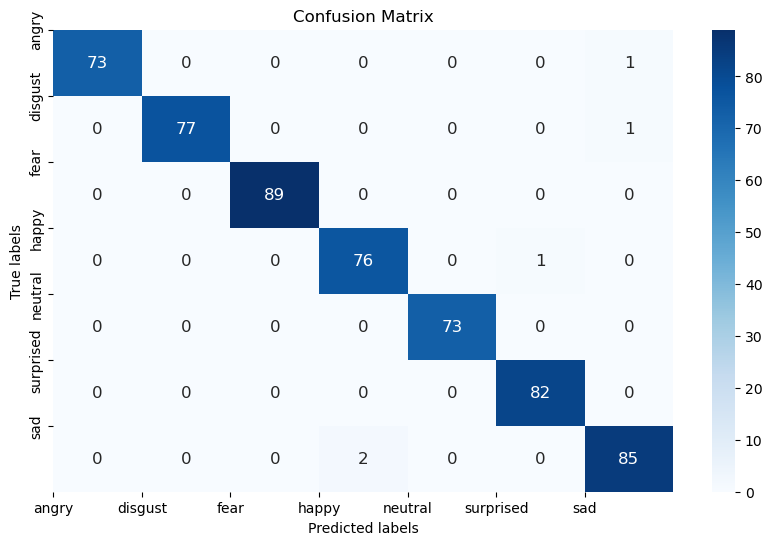

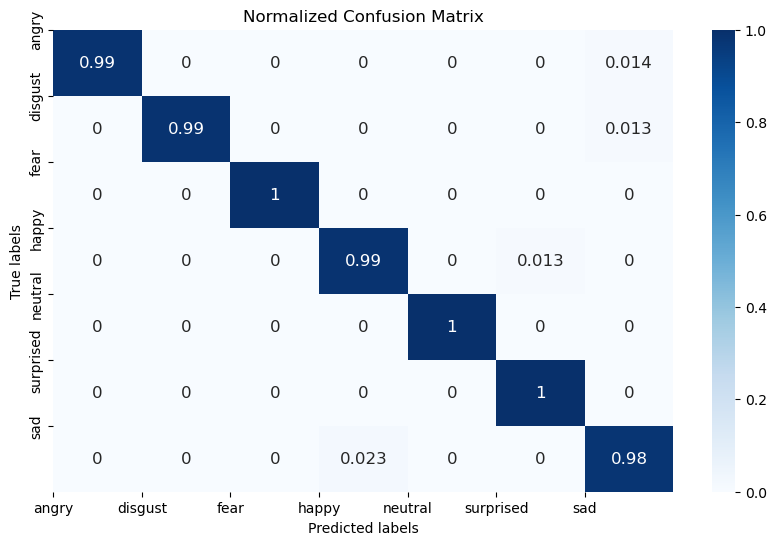

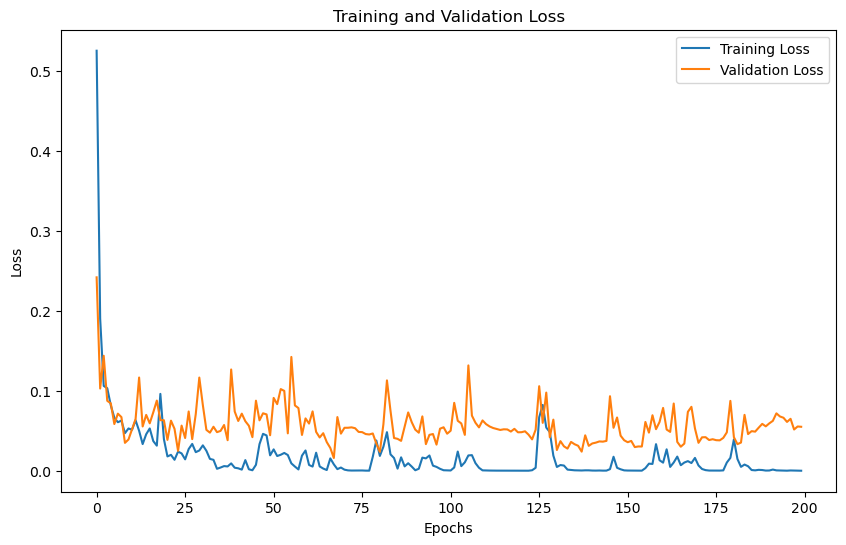

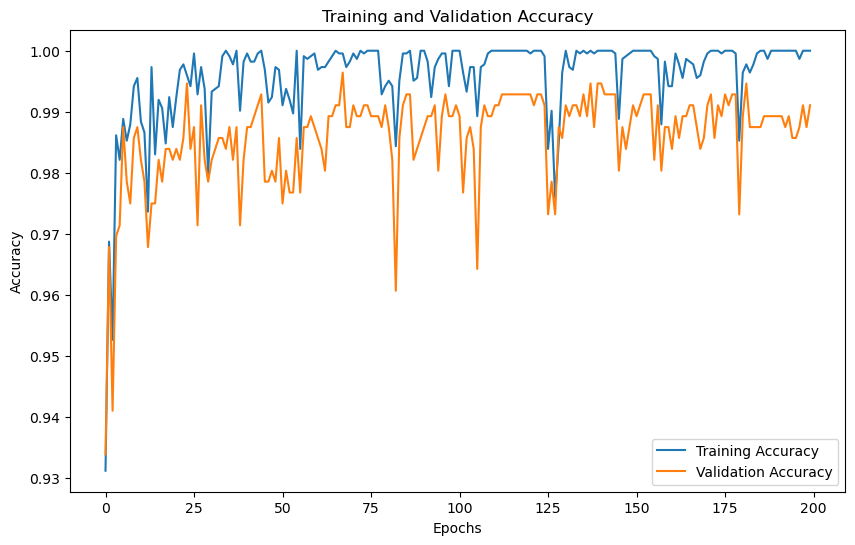

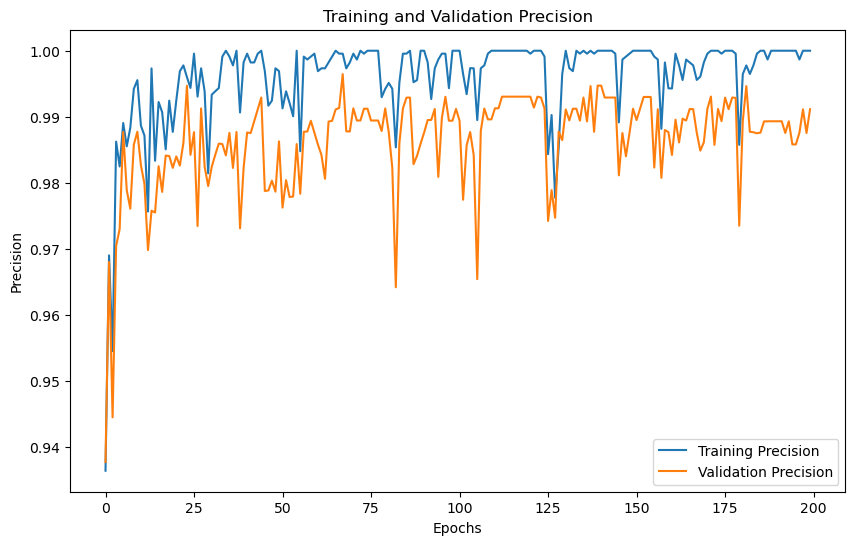

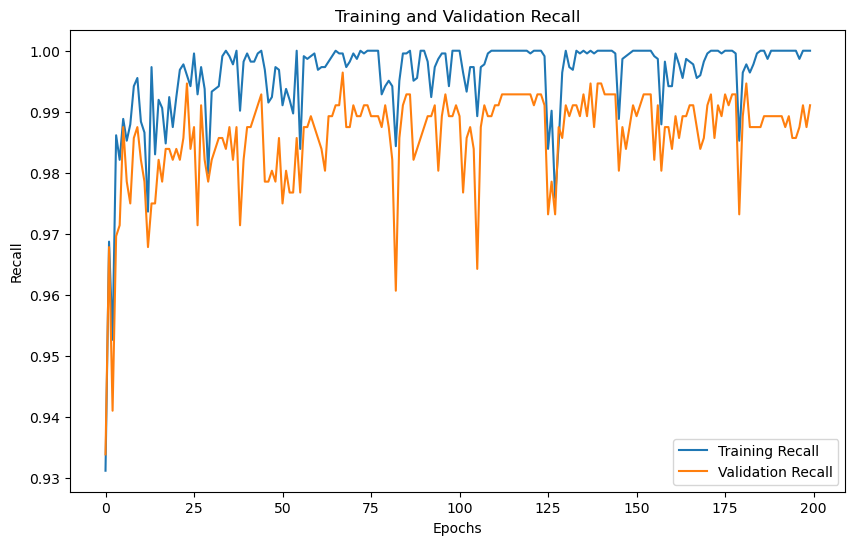

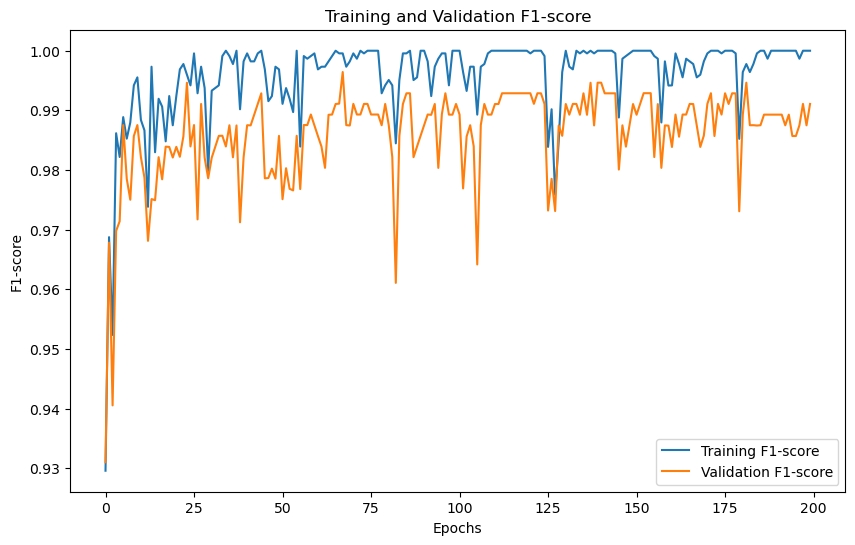

'Model Training and Evaluation Successfully completed'

In [15]:
train_model()

# TESS
# DWT 5
# N_MFCC 32

In [ ]:
train_model()

# TESS
# DWT 1
# N_MFCC 40

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 7
Input size for wavelet level 1 = 80
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (2800, 1, 80)
Y Shape : (2800, 7)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 0.5019, Training Accuracy: 0.9366, Training Precision:0.9408,Training Recall:0.9366,Training F1-Score:0.9367
Validation Loss: 0.1494, Validation Accuracy: 0.9571, Validation Precision:0.9594,Validation Recall:0.9571,Validation F1-Score:0.9574
Epoch [2/200],
Training Loss: 0.1793, Training Accuracy: 0.9353, Training Precision:0.9375,Training Recall:0.9353,Training F1-Score:0.9348
Validation Loss: 0.2005, Validation Accuracy: 0.9464, Validation Precision:0.9479,Validation Recall:0.9464,Validation F1-Score:0.9457
Epoch [3/200],
Training Loss: 0.1861, Training Accuracy: 0.9576, Training Precision:0.9591,Training Recall:0.9576,Training F1-Score:0.9576
Va

Epoch [30/200],
Training Loss: 0.0104, Training Accuracy: 0.9902, Training Precision:0.9905,Training Recall:0.9902,Training F1-Score:0.9902
Validation Loss: 0.0699, Validation Accuracy: 0.9857, Validation Precision:0.9864,Validation Recall:0.9857,Validation F1-Score:0.9858
Epoch [31/200],
Training Loss: 0.0363, Training Accuracy: 0.9911, Training Precision:0.9914,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 0.0527, Validation Accuracy: 0.9875, Validation Precision:0.9879,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [32/200],
Training Loss: 0.0661, Training Accuracy: 0.9821, Training Precision:0.9831,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 0.1130, Validation Accuracy: 0.9696, Validation Precision:0.9721,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [33/200],
Training Loss: 0.0302, Training Accuracy: 0.9911, Training Precision:0.9912,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 0.0615, Validation Ac

Epoch [60/200],
Training Loss: 0.0061, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 0.0217, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [61/200],
Training Loss: 0.0057, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0445, Validation Accuracy: 0.9893, Validation Precision:0.9896,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [62/200],
Training Loss: 0.0149, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0562, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [63/200],
Training Loss: 0.0189, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0626, Validation Ac

Epoch [90/200],
Training Loss: 0.0206, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0450, Validation Accuracy: 0.9875, Validation Precision:0.9880,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [91/200],
Training Loss: 0.0065, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0313, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [92/200],
Training Loss: 0.0069, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0287, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [93/200],
Training Loss: 0.0083, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0309, Validation Ac

Epoch [120/200],
Training Loss: 0.0251, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0358, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [121/200],
Training Loss: 0.0057, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0593, Validation Accuracy: 0.9857, Validation Precision:0.9861,Validation Recall:0.9857,Validation F1-Score:0.9858
Epoch [122/200],
Training Loss: 0.0224, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0470, Validation Accuracy: 0.9875, Validation Precision:0.9880,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [123/200],
Training Loss: 0.0070, Training Accuracy: 0.9906, Training Precision:0.9911,Training Recall:0.9906,Training F1-Score:0.9906
Validation Loss: 0.0549, Validatio

Epoch [150/200],
Training Loss: 0.0132, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 0.0382, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [151/200],
Training Loss: 0.0176, Training Accuracy: 0.9938, Training Precision:0.9939,Training Recall:0.9938,Training F1-Score:0.9938
Validation Loss: 0.0498, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [152/200],
Training Loss: 0.0083, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0476, Validation Accuracy: 0.9893, Validation Precision:0.9898,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [153/200],
Training Loss: 0.0094, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 0.0537, Validatio

Epoch [180/200],
Training Loss: 0.0018, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0478, Validation Accuracy: 0.9911, Validation Precision:0.9912,Validation Recall:0.9911,Validation F1-Score:0.9910
Epoch [181/200],
Training Loss: 0.0026, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 0.0631, Validation Accuracy: 0.9857, Validation Precision:0.9861,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [182/200],
Training Loss: 0.0075, Training Accuracy: 0.9960, Training Precision:0.9961,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 0.0674, Validation Accuracy: 0.9893, Validation Precision:0.9899,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [183/200],
Training Loss: 0.0174, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 0.0249, Validatio

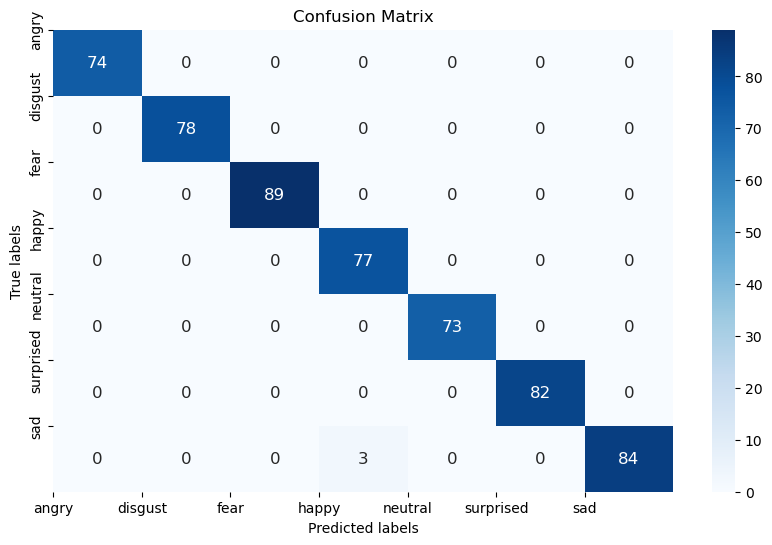

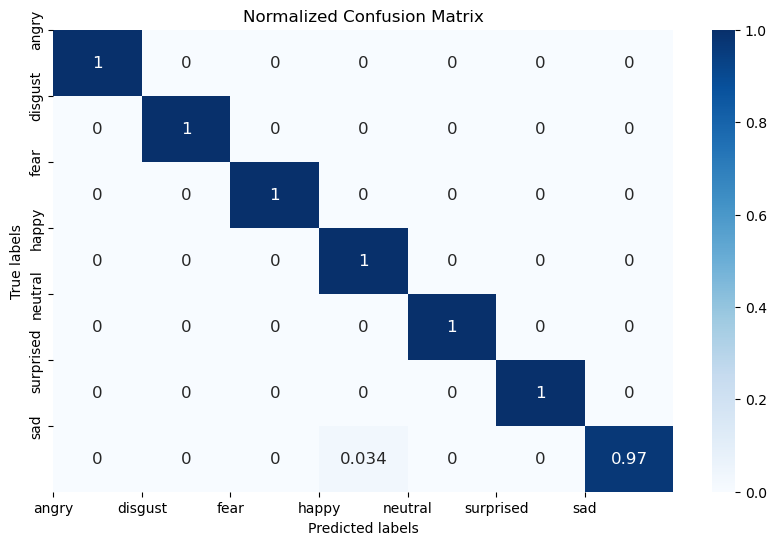

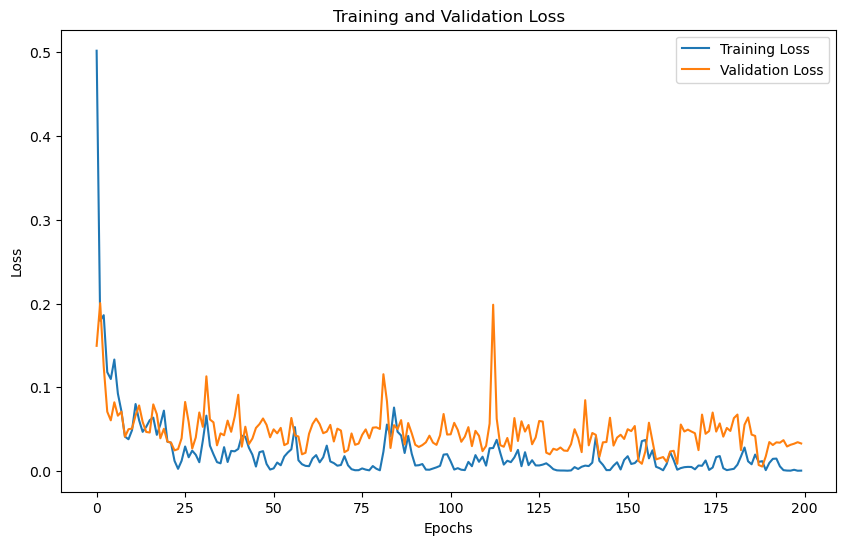

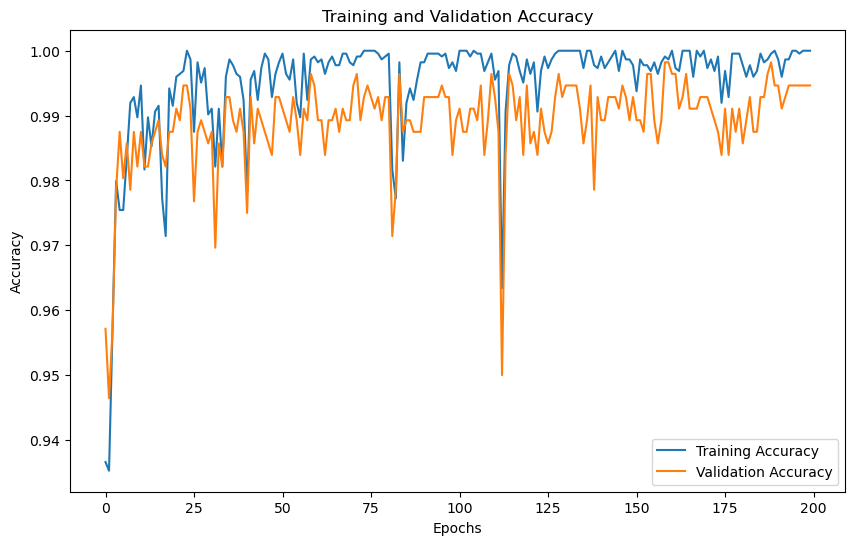

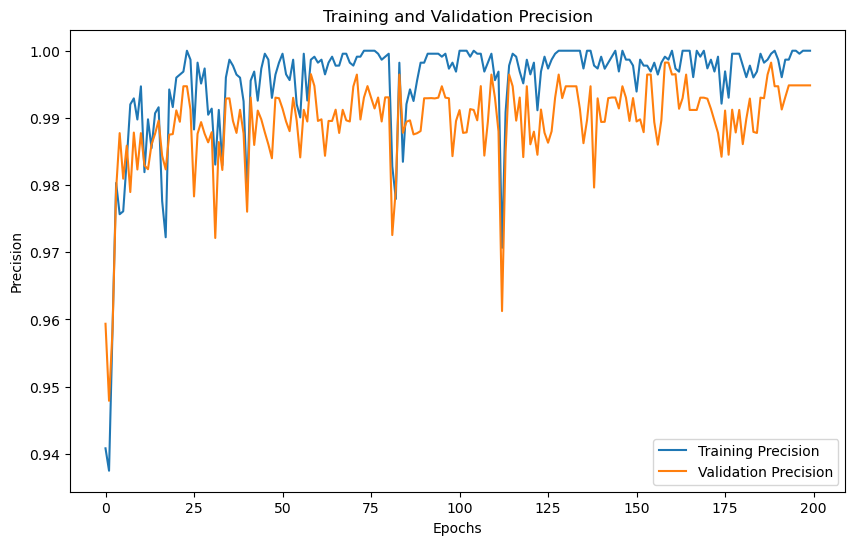

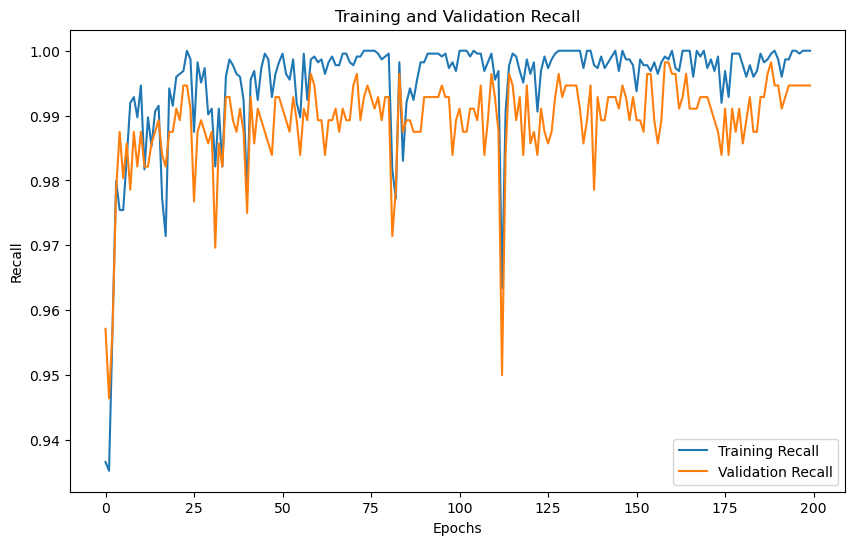

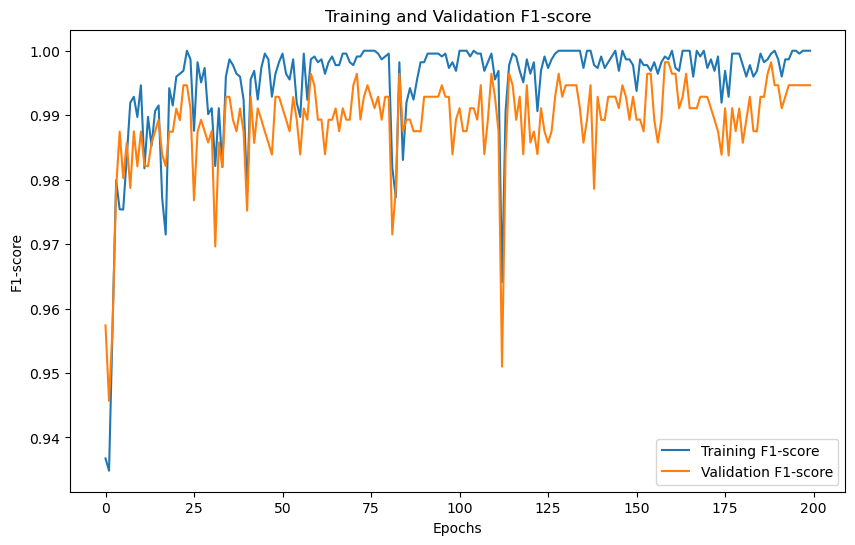

'Model Training and Evaluation Successfully completed'

In [24]:
train_model()

# CREMA
# DWT 3
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  3
Enter Number of MFCC coefficients : 32
No. of classes 6
Input size for wavelet level 3 = 128
Training with DWT level: 3
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (7442, 1, 128)
Y Shape : (7442, 6)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.5001, Training Accuracy: 0.4087, Training Precision:0.4173,Training Recall:0.4087,Training F1-Score:0.3666
Validation Loss: 1.4369, Validation Accuracy: 0.4036, Validation Precision:0.4076,Validation Recall:0.4036,Validation F1-Score:0.3689
Epoch [2/200],
Training Loss: 1.4354, Training Accuracy: 0.4072, Training Precision:0.4297,Training Recall:0.4072,Training F1-Score:0.3820
Validation Loss: 1.4276, Validation Accuracy: 0.4137, Validation Precision:0.4202,Validation Recall:0.4137,Validation F1-Score:0.3768
Epoch [3/200],
Training Loss: 1.4109, Training Accuracy: 0.4326, Training Precision:0.4197,Training Recall:0.4326,Training F1-Score:0.4113

Epoch [30/200],
Training Loss: 1.0898, Training Accuracy: 0.5985, Training Precision:0.6040,Training Recall:0.5985,Training F1-Score:0.5958
Validation Loss: 1.3301, Validation Accuracy: 0.4889, Validation Precision:0.4863,Validation Recall:0.4889,Validation F1-Score:0.4835
Epoch [31/200],
Training Loss: 1.0749, Training Accuracy: 0.6049, Training Precision:0.6157,Training Recall:0.6049,Training F1-Score:0.6030
Validation Loss: 1.3123, Validation Accuracy: 0.4849, Validation Precision:0.4858,Validation Recall:0.4849,Validation F1-Score:0.4794
Epoch [32/200],
Training Loss: 1.0483, Training Accuracy: 0.6330, Training Precision:0.6359,Training Recall:0.6330,Training F1-Score:0.6326
Validation Loss: 1.3549, Validation Accuracy: 0.4627, Validation Precision:0.4624,Validation Recall:0.4627,Validation F1-Score:0.4517
Epoch [33/200],
Training Loss: 1.0382, Training Accuracy: 0.6256, Training Precision:0.6277,Training Recall:0.6256,Training F1-Score:0.6220
Validation Loss: 1.3218, Validation Ac

Epoch [60/200],
Training Loss: 0.1649, Training Accuracy: 0.9488, Training Precision:0.9490,Training Recall:0.9488,Training F1-Score:0.9488
Validation Loss: 2.6086, Validation Accuracy: 0.4298, Validation Precision:0.4352,Validation Recall:0.4298,Validation F1-Score:0.4280
Epoch [61/200],
Training Loss: 0.1771, Training Accuracy: 0.9667, Training Precision:0.9667,Training Recall:0.9667,Training F1-Score:0.9667
Validation Loss: 2.5962, Validation Accuracy: 0.4419, Validation Precision:0.4393,Validation Recall:0.4419,Validation F1-Score:0.4369
Epoch [62/200],
Training Loss: 0.1224, Training Accuracy: 0.9632, Training Precision:0.9634,Training Recall:0.9632,Training F1-Score:0.9632
Validation Loss: 2.6280, Validation Accuracy: 0.4426, Validation Precision:0.4415,Validation Recall:0.4426,Validation F1-Score:0.4396
Epoch [63/200],
Training Loss: 0.1384, Training Accuracy: 0.9599, Training Precision:0.9611,Training Recall:0.9599,Training F1-Score:0.9600
Validation Loss: 2.7361, Validation Ac

Epoch [90/200],
Training Loss: 0.0605, Training Accuracy: 0.9755, Training Precision:0.9756,Training Recall:0.9755,Training F1-Score:0.9754
Validation Loss: 3.1138, Validation Accuracy: 0.4453, Validation Precision:0.4383,Validation Recall:0.4453,Validation F1-Score:0.4400
Epoch [91/200],
Training Loss: 0.0749, Training Accuracy: 0.9814, Training Precision:0.9814,Training Recall:0.9814,Training F1-Score:0.9814
Validation Loss: 3.0662, Validation Accuracy: 0.4547, Validation Precision:0.4527,Validation Recall:0.4547,Validation F1-Score:0.4518
Epoch [92/200],
Training Loss: 0.0690, Training Accuracy: 0.9820, Training Precision:0.9821,Training Recall:0.9820,Training F1-Score:0.9820
Validation Loss: 3.1156, Validation Accuracy: 0.4218, Validation Precision:0.4110,Validation Recall:0.4218,Validation F1-Score:0.4138
Epoch [93/200],
Training Loss: 0.0605, Training Accuracy: 0.9906, Training Precision:0.9906,Training Recall:0.9906,Training F1-Score:0.9906
Validation Loss: 3.0134, Validation Ac

Epoch [120/200],
Training Loss: 0.0348, Training Accuracy: 0.9867, Training Precision:0.9868,Training Recall:0.9867,Training F1-Score:0.9867
Validation Loss: 3.2064, Validation Accuracy: 0.4372, Validation Precision:0.4389,Validation Recall:0.4372,Validation F1-Score:0.4360
Epoch [121/200],
Training Loss: 0.0483, Training Accuracy: 0.9834, Training Precision:0.9835,Training Recall:0.9834,Training F1-Score:0.9834
Validation Loss: 3.2520, Validation Accuracy: 0.4392, Validation Precision:0.4277,Validation Recall:0.4392,Validation F1-Score:0.4309
Epoch [122/200],
Training Loss: 0.0402, Training Accuracy: 0.9889, Training Precision:0.9889,Training Recall:0.9889,Training F1-Score:0.9889
Validation Loss: 3.2032, Validation Accuracy: 0.4271, Validation Precision:0.4265,Validation Recall:0.4271,Validation F1-Score:0.4213
Epoch [123/200],
Training Loss: 0.0460, Training Accuracy: 0.9923, Training Precision:0.9923,Training Recall:0.9923,Training F1-Score:0.9923
Validation Loss: 3.0745, Validatio

Epoch [150/200],
Training Loss: 0.0191, Training Accuracy: 0.9953, Training Precision:0.9953,Training Recall:0.9953,Training F1-Score:0.9953
Validation Loss: 3.2775, Validation Accuracy: 0.4466, Validation Precision:0.4417,Validation Recall:0.4466,Validation F1-Score:0.4403
Epoch [151/200],
Training Loss: 0.0300, Training Accuracy: 0.9924, Training Precision:0.9925,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 3.3438, Validation Accuracy: 0.4285, Validation Precision:0.4234,Validation Recall:0.4285,Validation F1-Score:0.4251
Epoch [152/200],
Training Loss: 0.0268, Training Accuracy: 0.9908, Training Precision:0.9908,Training Recall:0.9908,Training F1-Score:0.9908
Validation Loss: 3.3223, Validation Accuracy: 0.4406, Validation Precision:0.4340,Validation Recall:0.4406,Validation F1-Score:0.4352
Epoch [153/200],
Training Loss: 0.0521, Training Accuracy: 0.9916, Training Precision:0.9916,Training Recall:0.9916,Training F1-Score:0.9916
Validation Loss: 3.1498, Validatio

Epoch [180/200],
Training Loss: 0.0336, Training Accuracy: 0.9961, Training Precision:0.9962,Training Recall:0.9961,Training F1-Score:0.9961
Validation Loss: 3.3110, Validation Accuracy: 0.4345, Validation Precision:0.4312,Validation Recall:0.4345,Validation F1-Score:0.4325
Epoch [181/200],
Training Loss: 0.0147, Training Accuracy: 0.9946, Training Precision:0.9946,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 3.4450, Validation Accuracy: 0.4359, Validation Precision:0.4330,Validation Recall:0.4359,Validation F1-Score:0.4325
Epoch [182/200],
Training Loss: 0.0318, Training Accuracy: 0.9874, Training Precision:0.9874,Training Recall:0.9874,Training F1-Score:0.9874
Validation Loss: 3.4013, Validation Accuracy: 0.4392, Validation Precision:0.4317,Validation Recall:0.4392,Validation F1-Score:0.4327
Epoch [183/200],
Training Loss: 0.0520, Training Accuracy: 0.9913, Training Precision:0.9913,Training Recall:0.9913,Training F1-Score:0.9913
Validation Loss: 3.2296, Validatio

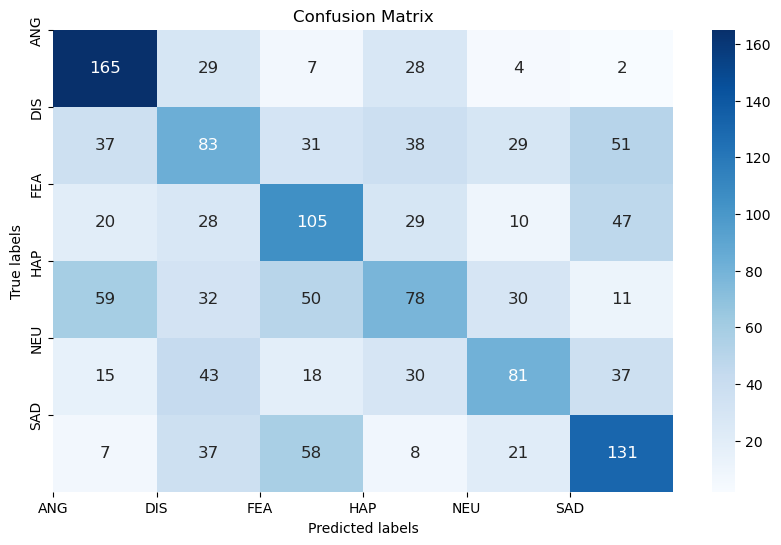

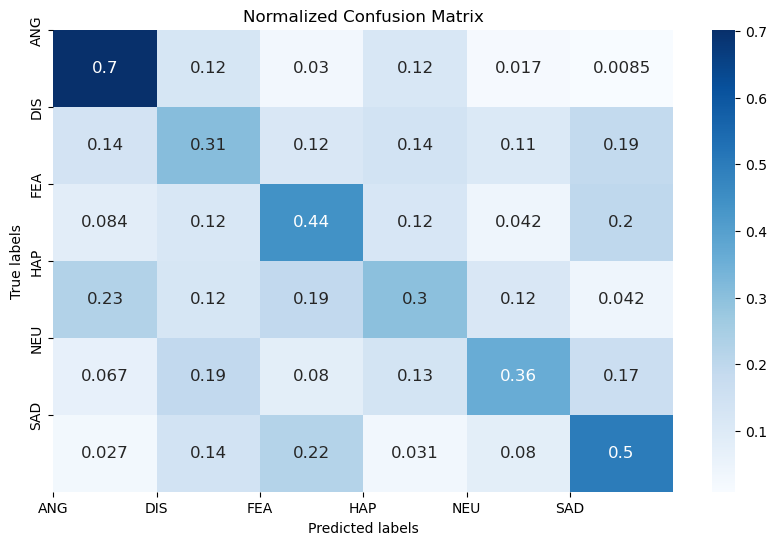

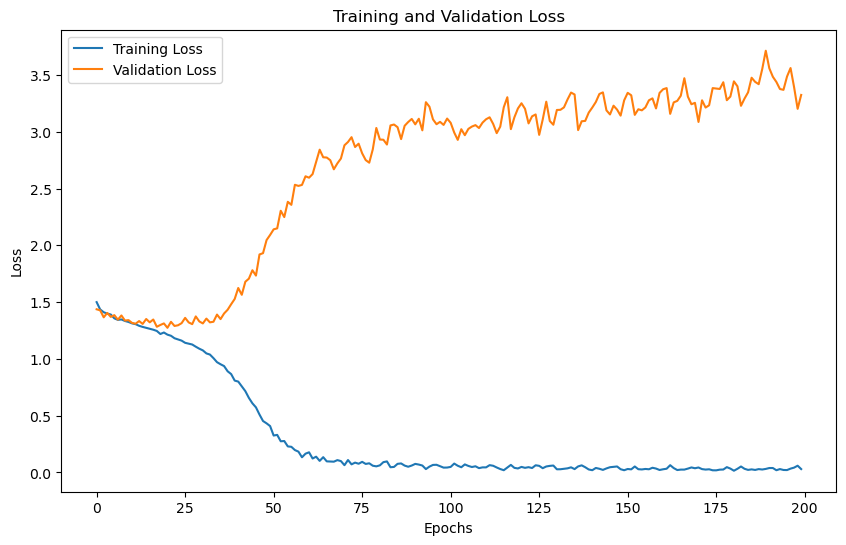

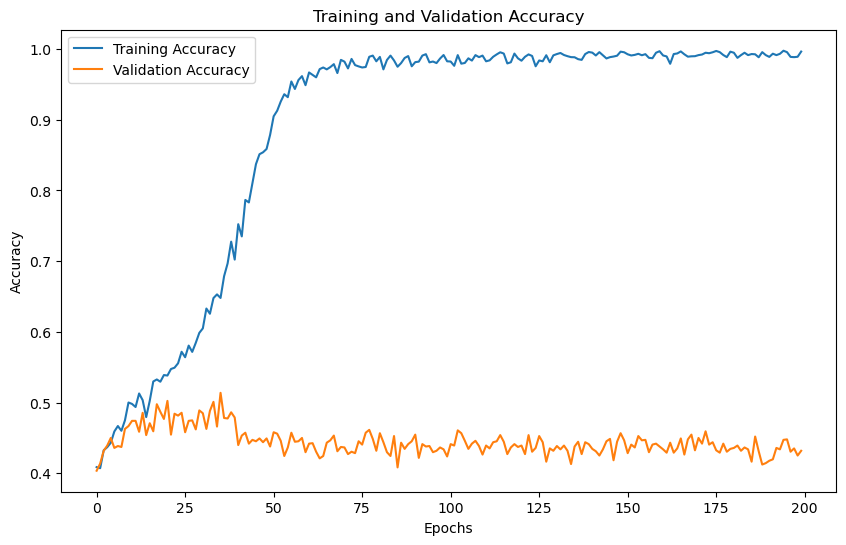

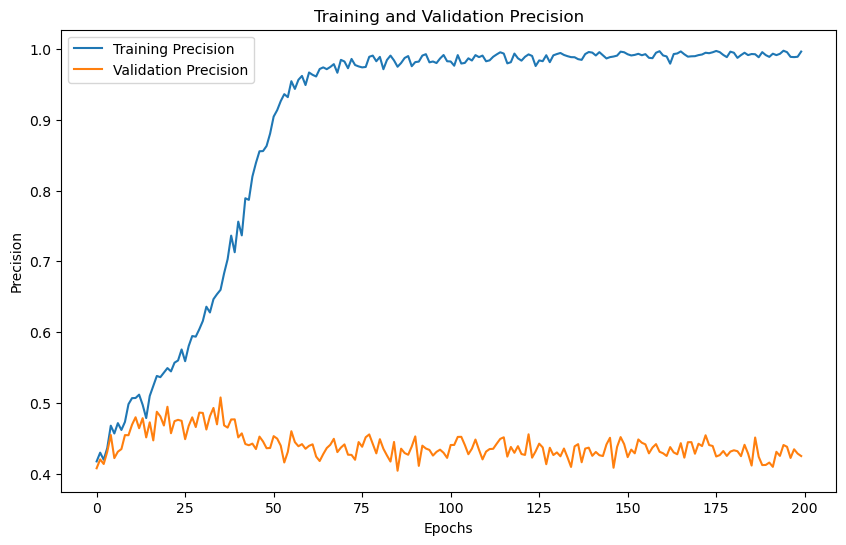

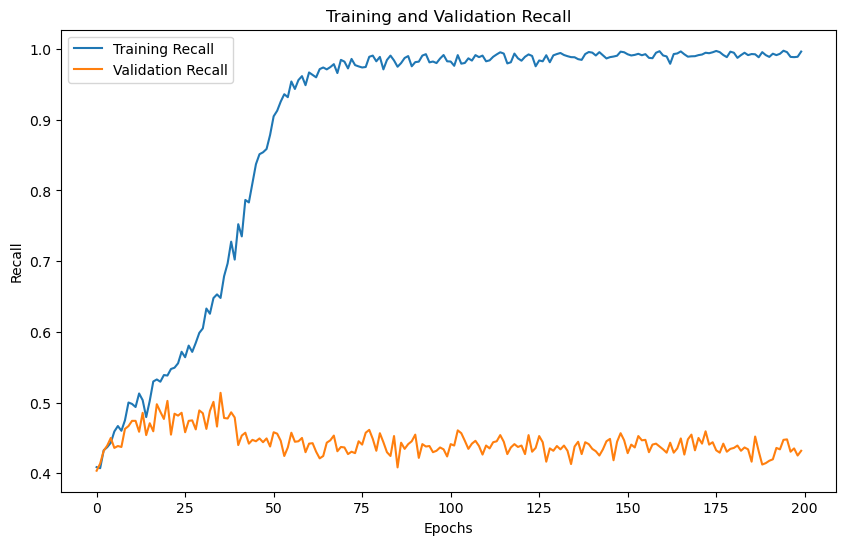

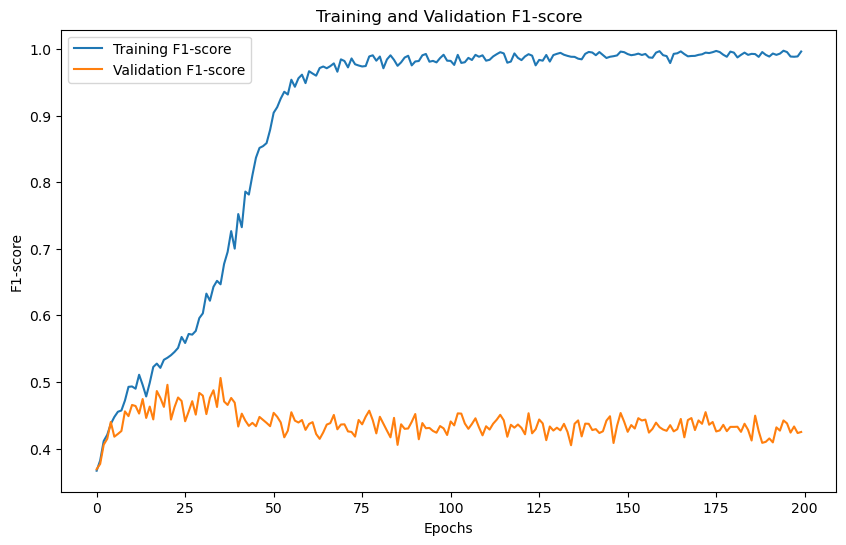

'Model Training and Evaluation Successfully completed'

In [11]:
train_model()

# CREMA
# DWT 1
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  1
Enter Number of MFCC coefficients : 32
No. of classes 6
Input size for wavelet level 1 = 64
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (7442, 1, 64)
Y Shape : (7442, 6)

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.5289, Training Accuracy: 0.3852, Training Precision:0.3538,Training Recall:0.3852,Training F1-Score:0.3418
Validation Loss: 1.4582, Validation Accuracy: 0.3989, Validation Precision:0.3669,Validation Recall:0.3989,Validation F1-Score:0.3643
Epoch [2/200],
Training Loss: 1.4691, Training Accuracy: 0.3953, Training Precision:0.4116,Training Recall:0.3953,Training F1-Score:0.3806
Validation Loss: 1.4747, Validation Accuracy: 0.3700, Validation Precision:0.4143,Validation Recall:0.3700,Validation F1-Score:0.3573
Epoch [3/200],
Training Loss: 1.4542, Training Accuracy: 0.3790, Training Precision:0.3930,Training Recall:0.3790,Training F1-Score:0.3259
V

Epoch [30/200],
Training Loss: 1.2566, Training Accuracy: 0.5147, Training Precision:0.5160,Training Recall:0.5147,Training F1-Score:0.5097
Validation Loss: 1.3314, Validation Accuracy: 0.4768, Validation Precision:0.4742,Validation Recall:0.4768,Validation F1-Score:0.4658
Epoch [31/200],
Training Loss: 1.2564, Training Accuracy: 0.5045, Training Precision:0.5031,Training Recall:0.5045,Training F1-Score:0.4983
Validation Loss: 1.3751, Validation Accuracy: 0.4466, Validation Precision:0.4450,Validation Recall:0.4466,Validation F1-Score:0.4376
Epoch [32/200],
Training Loss: 1.2625, Training Accuracy: 0.5167, Training Precision:0.5161,Training Recall:0.5167,Training F1-Score:0.5109
Validation Loss: 1.2913, Validation Accuracy: 0.4889, Validation Precision:0.4918,Validation Recall:0.4889,Validation F1-Score:0.4869
Epoch [33/200],
Training Loss: 1.2536, Training Accuracy: 0.5149, Training Precision:0.5106,Training Recall:0.5149,Training F1-Score:0.5050
Validation Loss: 1.4251, Validation Ac

Epoch [60/200],
Training Loss: 1.0851, Training Accuracy: 0.5994, Training Precision:0.6041,Training Recall:0.5994,Training F1-Score:0.6004
Validation Loss: 1.3334, Validation Accuracy: 0.4788, Validation Precision:0.4927,Validation Recall:0.4788,Validation F1-Score:0.4783
Epoch [61/200],
Training Loss: 1.0851, Training Accuracy: 0.5928, Training Precision:0.5998,Training Recall:0.5928,Training F1-Score:0.5906
Validation Loss: 1.3394, Validation Accuracy: 0.4788, Validation Precision:0.4947,Validation Recall:0.4788,Validation F1-Score:0.4755
Epoch [62/200],
Training Loss: 1.0730, Training Accuracy: 0.5955, Training Precision:0.5999,Training Recall:0.5955,Training F1-Score:0.5958
Validation Loss: 1.3490, Validation Accuracy: 0.4782, Validation Precision:0.4931,Validation Recall:0.4782,Validation F1-Score:0.4770
Epoch [63/200],
Training Loss: 1.0728, Training Accuracy: 0.6128, Training Precision:0.6167,Training Recall:0.6128,Training F1-Score:0.6111
Validation Loss: 1.2741, Validation Ac

Epoch [90/200],
Training Loss: 1.0803, Training Accuracy: 0.6096, Training Precision:0.6161,Training Recall:0.6096,Training F1-Score:0.6046
Validation Loss: 1.3915, Validation Accuracy: 0.4500, Validation Precision:0.4632,Validation Recall:0.4500,Validation F1-Score:0.4417
Epoch [91/200],
Training Loss: 1.0237, Training Accuracy: 0.6442, Training Precision:0.6479,Training Recall:0.6442,Training F1-Score:0.6406
Validation Loss: 1.3262, Validation Accuracy: 0.5050, Validation Precision:0.4960,Validation Recall:0.5050,Validation F1-Score:0.4958
Epoch [92/200],
Training Loss: 0.9757, Training Accuracy: 0.6592, Training Precision:0.6636,Training Recall:0.6592,Training F1-Score:0.6557
Validation Loss: 1.3684, Validation Accuracy: 0.4869, Validation Precision:0.4885,Validation Recall:0.4869,Validation F1-Score:0.4777
Epoch [93/200],
Training Loss: 0.9194, Training Accuracy: 0.6771, Training Precision:0.6769,Training Recall:0.6771,Training F1-Score:0.6753
Validation Loss: 1.4545, Validation Ac

Epoch [120/200],
Training Loss: 0.8657, Training Accuracy: 0.8246, Training Precision:0.8274,Training Recall:0.8246,Training F1-Score:0.8239
Validation Loss: 1.7817, Validation Accuracy: 0.4406, Validation Precision:0.4381,Validation Recall:0.4406,Validation F1-Score:0.4353
Epoch [121/200],
Training Loss: 0.4418, Training Accuracy: 0.8750, Training Precision:0.8771,Training Recall:0.8750,Training F1-Score:0.8751
Validation Loss: 2.1353, Validation Accuracy: 0.4224, Validation Precision:0.4303,Validation Recall:0.4224,Validation F1-Score:0.4142
Epoch [122/200],
Training Loss: 0.3801, Training Accuracy: 0.8802, Training Precision:0.8803,Training Recall:0.8802,Training F1-Score:0.8800
Validation Loss: 2.2794, Validation Accuracy: 0.4164, Validation Precision:0.4187,Validation Recall:0.4164,Validation F1-Score:0.4079
Epoch [123/200],
Training Loss: 0.3387, Training Accuracy: 0.8881, Training Precision:0.8879,Training Recall:0.8881,Training F1-Score:0.8875
Validation Loss: 2.3154, Validatio

Epoch [150/200],
Training Loss: 0.1546, Training Accuracy: 0.9551, Training Precision:0.9552,Training Recall:0.9551,Training F1-Score:0.9551
Validation Loss: 2.9212, Validation Accuracy: 0.4231, Validation Precision:0.4238,Validation Recall:0.4231,Validation F1-Score:0.4147
Epoch [151/200],
Training Loss: 0.1352, Training Accuracy: 0.9562, Training Precision:0.9571,Training Recall:0.9562,Training F1-Score:0.9563
Validation Loss: 2.7713, Validation Accuracy: 0.4506, Validation Precision:0.4399,Validation Recall:0.4506,Validation F1-Score:0.4389
Epoch [152/200],
Training Loss: 0.1404, Training Accuracy: 0.9656, Training Precision:0.9658,Training Recall:0.9656,Training F1-Score:0.9656
Validation Loss: 2.7906, Validation Accuracy: 0.4547, Validation Precision:0.4587,Validation Recall:0.4547,Validation F1-Score:0.4508
Epoch [153/200],
Training Loss: 0.1177, Training Accuracy: 0.9624, Training Precision:0.9627,Training Recall:0.9624,Training F1-Score:0.9624
Validation Loss: 2.8585, Validatio

Epoch [180/200],
Training Loss: 0.0950, Training Accuracy: 0.9787, Training Precision:0.9787,Training Recall:0.9787,Training F1-Score:0.9787
Validation Loss: 3.0396, Validation Accuracy: 0.4392, Validation Precision:0.4403,Validation Recall:0.4392,Validation F1-Score:0.4344
Epoch [181/200],
Training Loss: 0.0738, Training Accuracy: 0.9735, Training Precision:0.9735,Training Recall:0.9735,Training F1-Score:0.9734
Validation Loss: 3.2642, Validation Accuracy: 0.4244, Validation Precision:0.4281,Validation Recall:0.4244,Validation F1-Score:0.4119
Epoch [182/200],
Training Loss: 0.0907, Training Accuracy: 0.9777, Training Precision:0.9777,Training Recall:0.9777,Training F1-Score:0.9776
Validation Loss: 3.1317, Validation Accuracy: 0.4379, Validation Precision:0.4423,Validation Recall:0.4379,Validation F1-Score:0.4320
Epoch [183/200],
Training Loss: 0.0820, Training Accuracy: 0.9731, Training Precision:0.9731,Training Recall:0.9731,Training F1-Score:0.9731
Validation Loss: 3.0515, Validatio

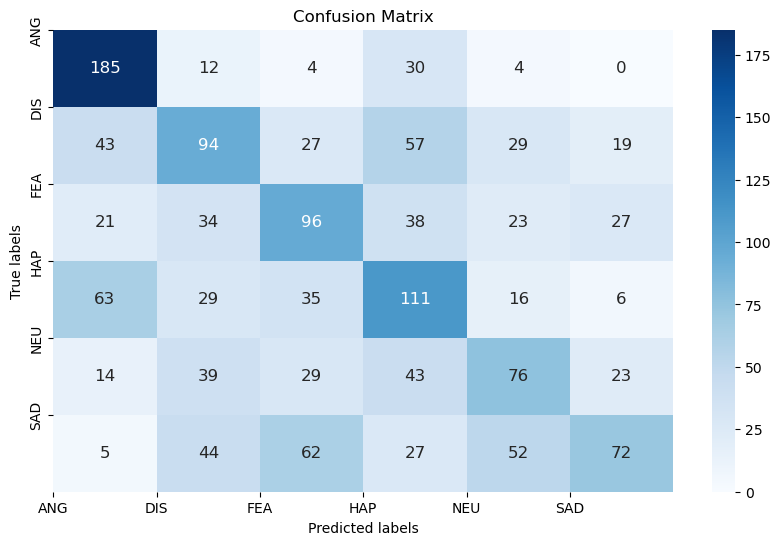

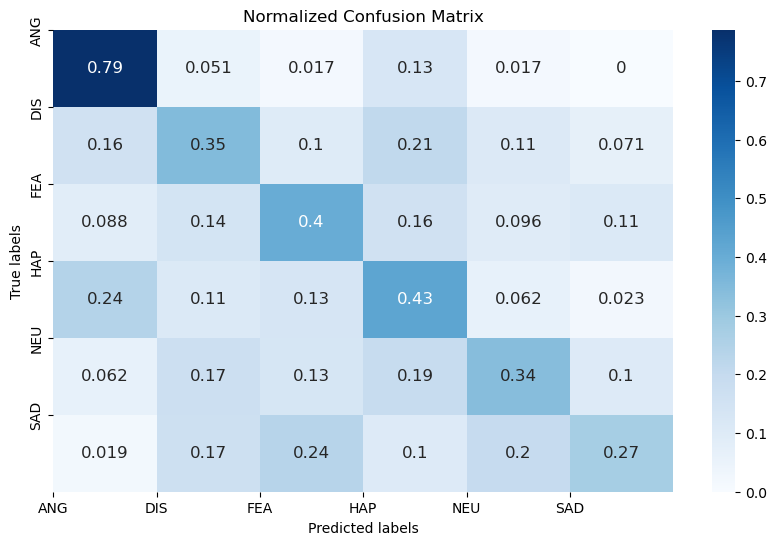

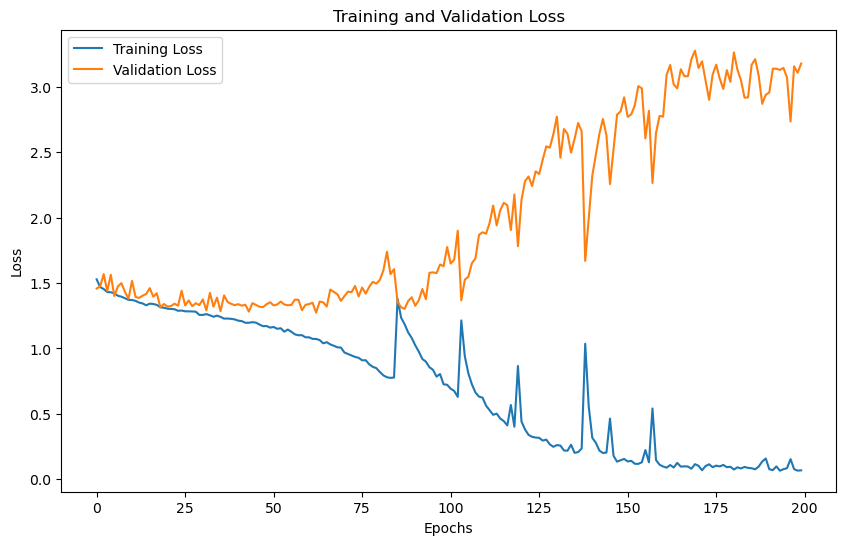

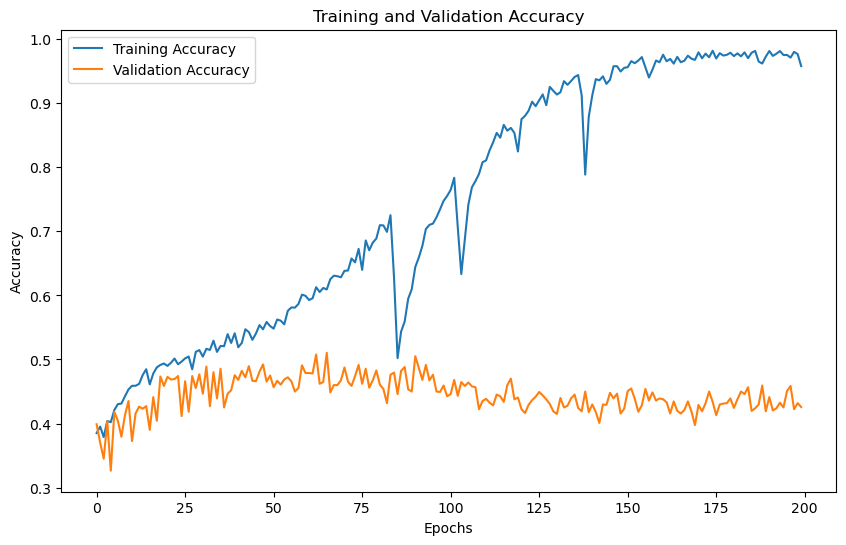

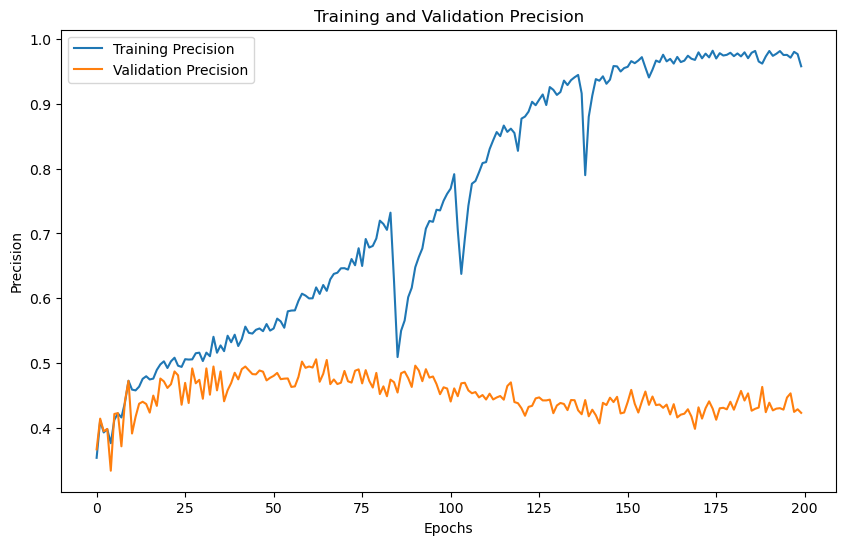

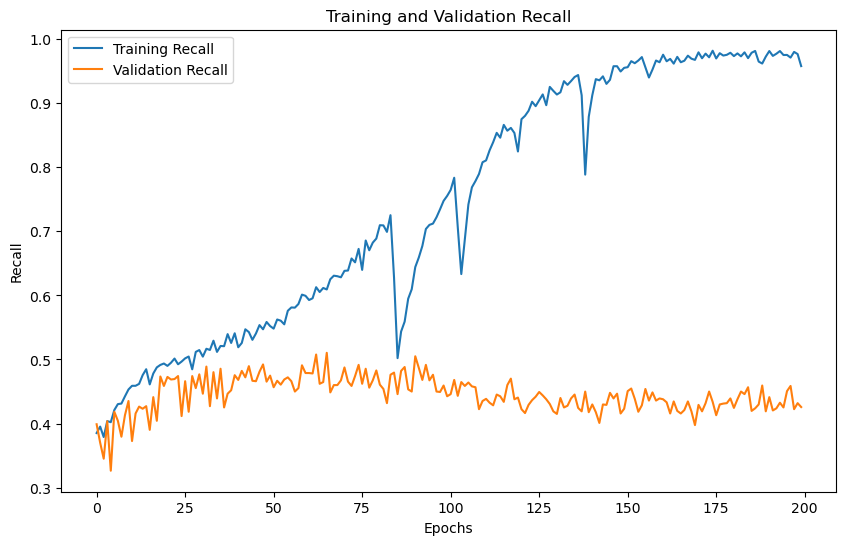

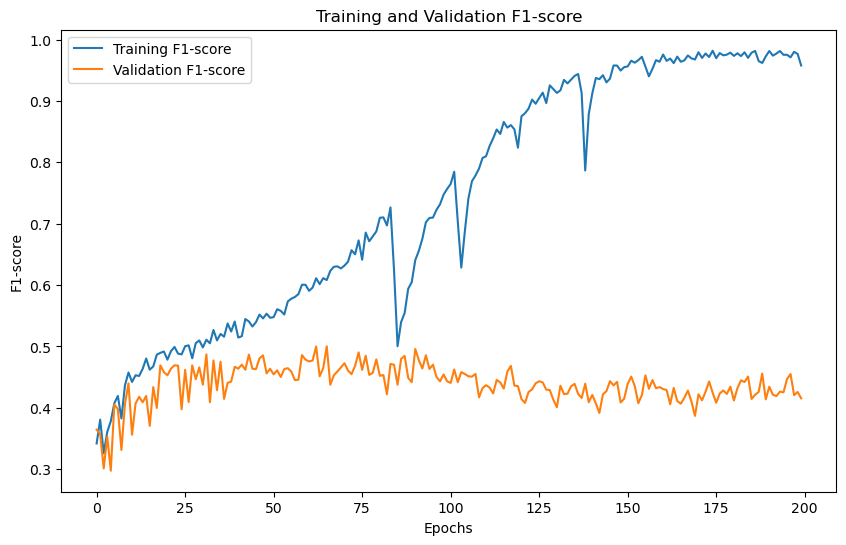

'Model Training and Evaluation Successfully completed'

In [16]:
train_model()

# changing test train split

# SAVEE
# DWT 1
# N_MFCC 24
# 501 epoch

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 24
No. of classes 6
Input size for wavelet level 1 = 48
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (480, 1, 48)
Y Shape : (480, 6)

Enter no. of epochs 501
Epoch [1/501],
Training Loss: 1.5922, Training Accuracy: 0.4851, Training Precision:0.5198,Training Recall:0.4851,Training F1-Score:0.4308
Validation Loss: 1.6953, Validation Accuracy: 0.2986, Validation Precision:0.1998,Validation Recall:0.2986,Validation F1-Score:0.2259
Epoch [2/501],
Training Loss: 1.3079, Training Accuracy: 0.5655, Training Precision:0.5867,Training Recall:0.5655,Training F1-Score:0.5417
Validation Loss: 1.3957, Validation Accuracy: 0.4167, Validation Precision:0.2926,Validation Recall:0.4167,Validation F1-Score:0.3372
Epoch [3/501],
Training Loss: 1.1234, Training Accuracy: 0.5952, Training Precision:0.5838,Training Recall:0.5952,Training F1-Score:0.5787
Val

Epoch [30/501],
Training Loss: 0.6801, Training Accuracy: 0.7738, Training Precision:0.7767,Training Recall:0.7738,Training F1-Score:0.7741
Validation Loss: 1.2762, Validation Accuracy: 0.5347, Validation Precision:0.5375,Validation Recall:0.5347,Validation F1-Score:0.5308
Epoch [31/501],
Training Loss: 0.6778, Training Accuracy: 0.7887, Training Precision:0.7941,Training Recall:0.7887,Training F1-Score:0.7849
Validation Loss: 0.9607, Validation Accuracy: 0.6736, Validation Precision:0.6744,Validation Recall:0.6736,Validation F1-Score:0.6637
Epoch [32/501],
Training Loss: 0.5860, Training Accuracy: 0.8274, Training Precision:0.8327,Training Recall:0.8274,Training F1-Score:0.8259
Validation Loss: 0.7900, Validation Accuracy: 0.6944, Validation Precision:0.6853,Validation Recall:0.6944,Validation F1-Score:0.6793
Epoch [33/501],
Training Loss: 0.5900, Training Accuracy: 0.8006, Training Precision:0.8048,Training Recall:0.8006,Training F1-Score:0.7997
Validation Loss: 1.0009, Validation Ac

Epoch [60/501],
Training Loss: 0.4097, Training Accuracy: 0.8631, Training Precision:0.8633,Training Recall:0.8631,Training F1-Score:0.8625
Validation Loss: 0.8586, Validation Accuracy: 0.6944, Validation Precision:0.6972,Validation Recall:0.6944,Validation F1-Score:0.6859
Epoch [61/501],
Training Loss: 0.3796, Training Accuracy: 0.8661, Training Precision:0.8756,Training Recall:0.8661,Training F1-Score:0.8647
Validation Loss: 1.0229, Validation Accuracy: 0.6667, Validation Precision:0.7101,Validation Recall:0.6667,Validation F1-Score:0.6647
Epoch [62/501],
Training Loss: 0.4021, Training Accuracy: 0.8899, Training Precision:0.8951,Training Recall:0.8899,Training F1-Score:0.8886
Validation Loss: 0.9719, Validation Accuracy: 0.6806, Validation Precision:0.7225,Validation Recall:0.6806,Validation F1-Score:0.6618
Epoch [63/501],
Training Loss: 0.4707, Training Accuracy: 0.8333, Training Precision:0.8320,Training Recall:0.8333,Training F1-Score:0.8320
Validation Loss: 0.9430, Validation Ac

Epoch [90/501],
Training Loss: 0.4534, Training Accuracy: 0.8571, Training Precision:0.8604,Training Recall:0.8571,Training F1-Score:0.8557
Validation Loss: 1.0496, Validation Accuracy: 0.6181, Validation Precision:0.6802,Validation Recall:0.6181,Validation F1-Score:0.6252
Epoch [91/501],
Training Loss: 0.4743, Training Accuracy: 0.8482, Training Precision:0.8514,Training Recall:0.8482,Training F1-Score:0.8482
Validation Loss: 1.1064, Validation Accuracy: 0.6597, Validation Precision:0.7027,Validation Recall:0.6597,Validation F1-Score:0.6699
Epoch [92/501],
Training Loss: 0.4502, Training Accuracy: 0.8333, Training Precision:0.8388,Training Recall:0.8333,Training F1-Score:0.8334
Validation Loss: 1.0482, Validation Accuracy: 0.6528, Validation Precision:0.6967,Validation Recall:0.6528,Validation F1-Score:0.6485
Epoch [93/501],
Training Loss: 0.3750, Training Accuracy: 0.8690, Training Precision:0.8732,Training Recall:0.8690,Training F1-Score:0.8679
Validation Loss: 0.9275, Validation Ac

Epoch [120/501],
Training Loss: 0.2912, Training Accuracy: 0.9077, Training Precision:0.9176,Training Recall:0.9077,Training F1-Score:0.9083
Validation Loss: 1.1482, Validation Accuracy: 0.6736, Validation Precision:0.6786,Validation Recall:0.6736,Validation F1-Score:0.6602
Epoch [121/501],
Training Loss: 0.3633, Training Accuracy: 0.8571, Training Precision:0.8716,Training Recall:0.8571,Training F1-Score:0.8565
Validation Loss: 1.0645, Validation Accuracy: 0.6736, Validation Precision:0.6765,Validation Recall:0.6736,Validation F1-Score:0.6578
Epoch [122/501],
Training Loss: 0.3787, Training Accuracy: 0.8750, Training Precision:0.8784,Training Recall:0.8750,Training F1-Score:0.8708
Validation Loss: 1.0937, Validation Accuracy: 0.6597, Validation Precision:0.6779,Validation Recall:0.6597,Validation F1-Score:0.6554
Epoch [123/501],
Training Loss: 0.4111, Training Accuracy: 0.8780, Training Precision:0.8815,Training Recall:0.8780,Training F1-Score:0.8769
Validation Loss: 1.0254, Validatio

...

Epoch [360/501],
Training Loss: 0.1193, Training Accuracy: 0.9762, Training Precision:0.9763,Training Recall:0.9762,Training F1-Score:0.9761
Validation Loss: 1.4544, Validation Accuracy: 0.6389, Validation Precision:0.6513,Validation Recall:0.6389,Validation F1-Score:0.6395
Epoch [361/501],
Training Loss: 0.0920, Training Accuracy: 0.9792, Training Precision:0.9800,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.2835, Validation Accuracy: 0.6528, Validation Precision:0.6635,Validation Recall:0.6528,Validation F1-Score:0.6510
Epoch [362/501],
Training Loss: 0.0828, Training Accuracy: 0.9792, Training Precision:0.9795,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.2771, Validation Accuracy: 0.6736, Validation Precision:0.6771,Validation Recall:0.6736,Validation F1-Score:0.6706
Epoch [363/501],
Training Loss: 0.1046, Training Accuracy: 0.9702, Training Precision:0.9712,Training Recall:0.9702,Training F1-Score:0.9702
Validation Loss: 1.0802, Validatio

Epoch [390/501],
Training Loss: 0.0689, Training Accuracy: 0.9762, Training Precision:0.9763,Training Recall:0.9762,Training F1-Score:0.9761
Validation Loss: 1.0597, Validation Accuracy: 0.7083, Validation Precision:0.7345,Validation Recall:0.7083,Validation F1-Score:0.7047
Epoch [391/501],
Training Loss: 0.0475, Training Accuracy: 0.9821, Training Precision:0.9826,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 1.0455, Validation Accuracy: 0.7222, Validation Precision:0.7407,Validation Recall:0.7222,Validation F1-Score:0.7201
Epoch [392/501],
Training Loss: 0.0670, Training Accuracy: 0.9940, Training Precision:0.9940,Training Recall:0.9940,Training F1-Score:0.9940
Validation Loss: 1.1073, Validation Accuracy: 0.7014, Validation Precision:0.7109,Validation Recall:0.7014,Validation F1-Score:0.6998
Epoch [393/501],
Training Loss: 0.0333, Training Accuracy: 0.9970, Training Precision:0.9971,Training Recall:0.9970,Training F1-Score:0.9970
Validation Loss: 1.1916, Validatio

Epoch [420/501],
Training Loss: 0.1622, Training Accuracy: 0.9345, Training Precision:0.9413,Training Recall:0.9345,Training F1-Score:0.9354
Validation Loss: 1.4987, Validation Accuracy: 0.6806, Validation Precision:0.7101,Validation Recall:0.6806,Validation F1-Score:0.6805
Epoch [421/501],
Training Loss: 0.1249, Training Accuracy: 0.9583, Training Precision:0.9609,Training Recall:0.9583,Training F1-Score:0.9586
Validation Loss: 1.4076, Validation Accuracy: 0.6389, Validation Precision:0.6470,Validation Recall:0.6389,Validation F1-Score:0.6361
Epoch [422/501],
Training Loss: 0.1026, Training Accuracy: 0.9732, Training Precision:0.9735,Training Recall:0.9732,Training F1-Score:0.9732
Validation Loss: 1.2555, Validation Accuracy: 0.6806, Validation Precision:0.6898,Validation Recall:0.6806,Validation F1-Score:0.6791
Epoch [423/501],
Training Loss: 0.1208, Training Accuracy: 0.9673, Training Precision:0.9681,Training Recall:0.9673,Training F1-Score:0.9673
Validation Loss: 1.2571, Validatio

Epoch [450/501],
Training Loss: 0.1324, Training Accuracy: 0.9792, Training Precision:0.9796,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 0.9746, Validation Accuracy: 0.7222, Validation Precision:0.7156,Validation Recall:0.7222,Validation F1-Score:0.7145
Epoch [451/501],
Training Loss: 0.0447, Training Accuracy: 0.9673, Training Precision:0.9682,Training Recall:0.9673,Training F1-Score:0.9669
Validation Loss: 1.1218, Validation Accuracy: 0.6875, Validation Precision:0.7042,Validation Recall:0.6875,Validation F1-Score:0.6777
Epoch [452/501],
Training Loss: 0.1197, Training Accuracy: 0.9524, Training Precision:0.9533,Training Recall:0.9524,Training F1-Score:0.9519
Validation Loss: 1.3184, Validation Accuracy: 0.6528, Validation Precision:0.6591,Validation Recall:0.6528,Validation F1-Score:0.6485
Epoch [453/501],
Training Loss: 0.1739, Training Accuracy: 0.9702, Training Precision:0.9705,Training Recall:0.9702,Training F1-Score:0.9702
Validation Loss: 1.2562, Validatio

Epoch [480/501],
Training Loss: 0.0262, Training Accuracy: 0.9970, Training Precision:0.9971,Training Recall:0.9970,Training F1-Score:0.9970
Validation Loss: 1.3423, Validation Accuracy: 0.7153, Validation Precision:0.7085,Validation Recall:0.7153,Validation F1-Score:0.7094
Epoch [481/501],
Training Loss: 0.0327, Training Accuracy: 0.9881, Training Precision:0.9886,Training Recall:0.9881,Training F1-Score:0.9881
Validation Loss: 1.4251, Validation Accuracy: 0.6875, Validation Precision:0.6875,Validation Recall:0.6875,Validation F1-Score:0.6833
Epoch [482/501],
Training Loss: 0.0719, Training Accuracy: 0.9911, Training Precision:0.9913,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.3650, Validation Accuracy: 0.6667, Validation Precision:0.6612,Validation Recall:0.6667,Validation F1-Score:0.6604
Epoch [483/501],
Training Loss: 0.0308, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.3391, Validatio

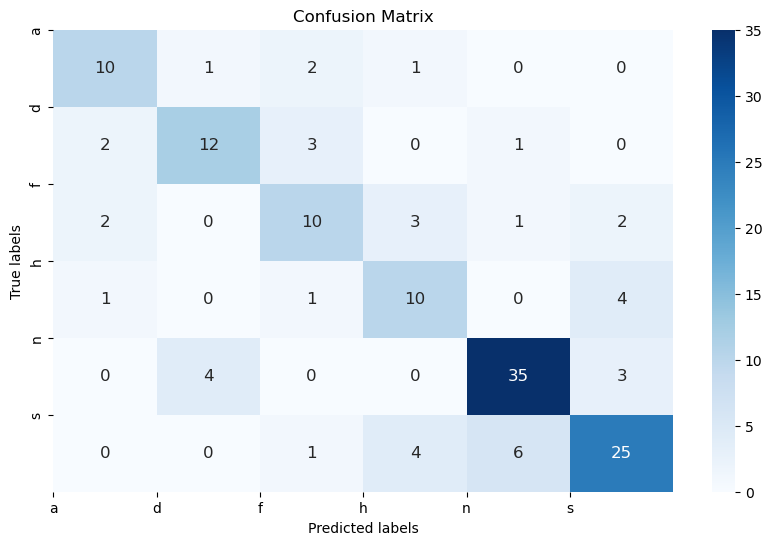

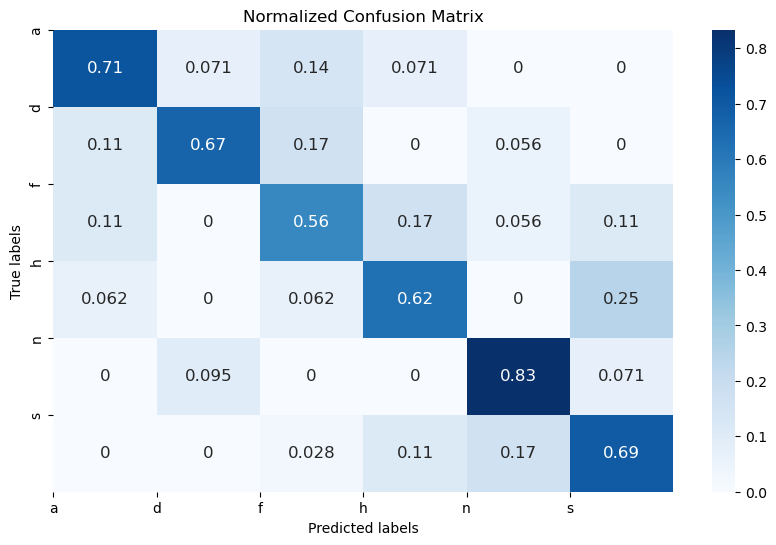

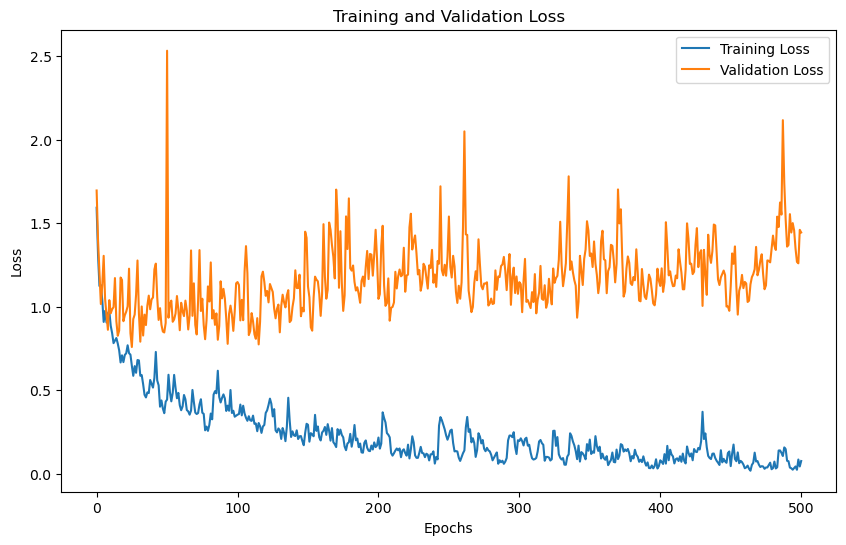

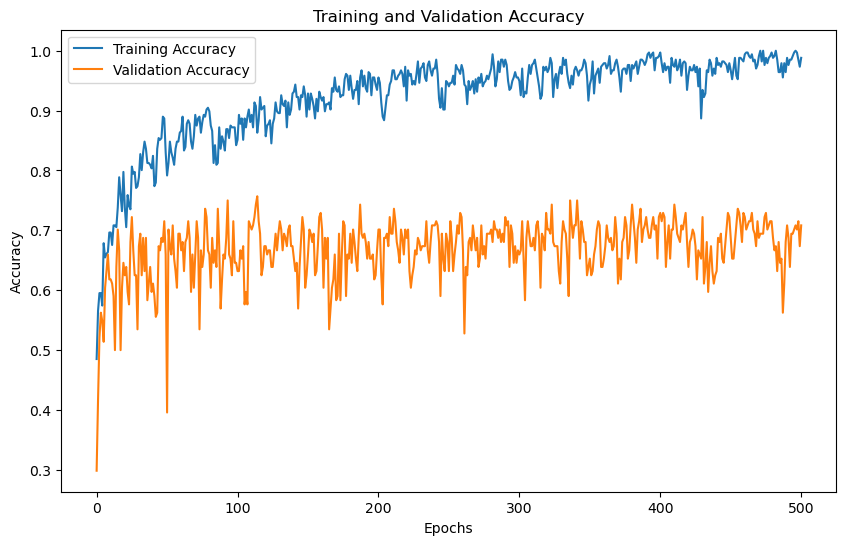

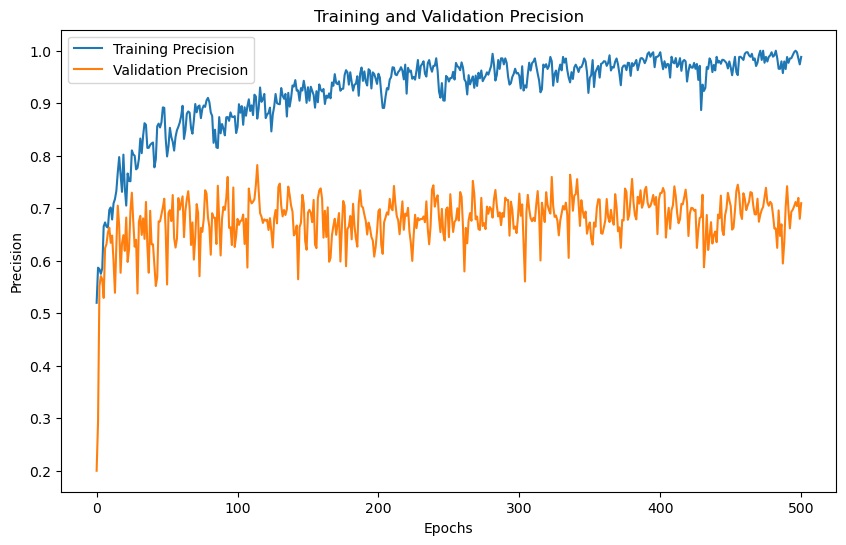

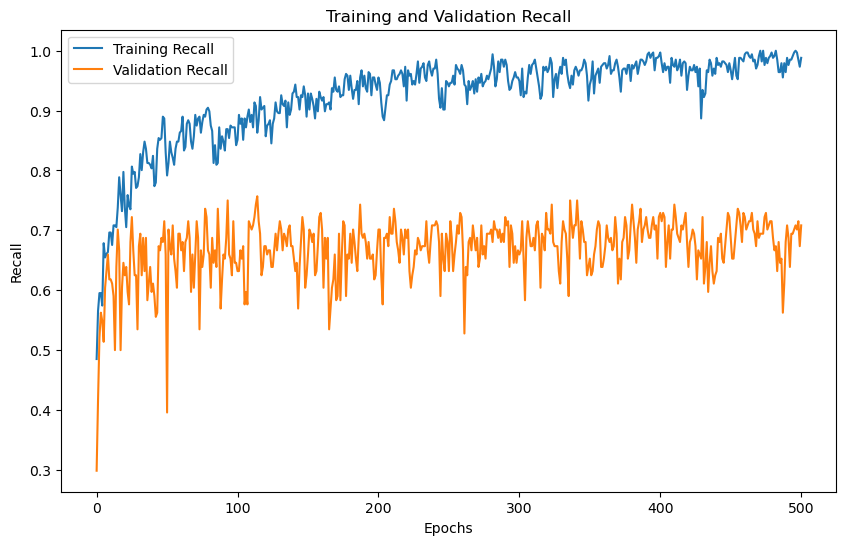

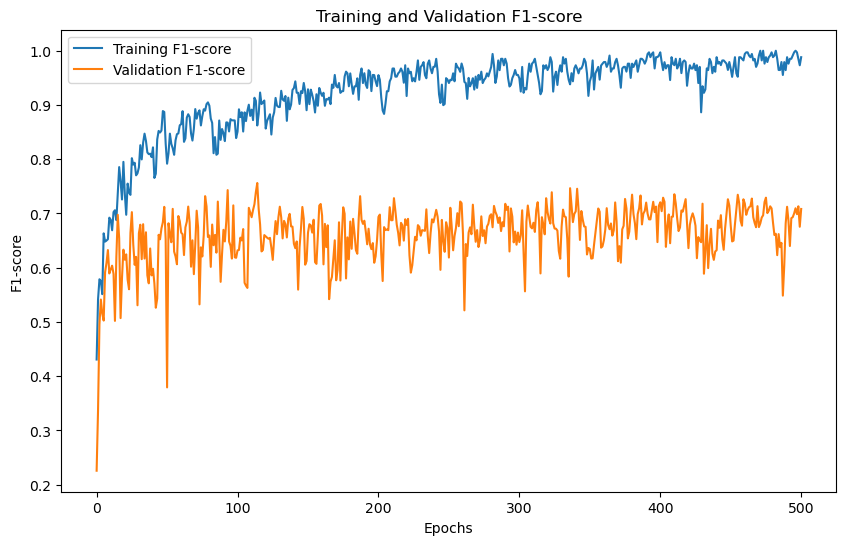

'Model Training and Evaluation Successfully completed'

In [11]:
train_model()

# RAVDESS
# DWT 1
# N_MFCC 24
# 501 epoch

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  1
Enter Number of MFCC coefficients : 24
No. of classes 8
Input size for wavelet level 1 = 48
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (1440, 1, 48)
Y Shape : (1440, 8)

Enter no. of epochs 501
Epoch [1/501],
Training Loss: 1.9183, Training Accuracy: 0.3403, Training Precision:0.3448,Training Recall:0.3403,Training F1-Score:0.3294
Validation Loss: 1.7366, Validation Accuracy: 0.3287, Validation Precision:0.3495,Validation Recall:0.3287,Validation F1-Score:0.3198
Epoch [2/501],
Training Loss: 1.7277, Training Accuracy: 0.3710, Training Precision:0.4038,Training Recall:0.3710,Training F1-Score:0.3505
Validation Loss: 1.5966, Validation Accuracy: 0.4005, Validation Precision:0.3779,Validation Recall:0.4005,Validation F1-Score:0.3746
Epoch [3/501],
Training Loss: 1.6077, Training Accuracy: 0.4226, Training Precision:0.4314,Training Recall:0.4226,Training F1-Score:0.4123

Epoch [30/501],
Training Loss: 1.0492, Training Accuracy: 0.6607, Training Precision:0.6667,Training Recall:0.6607,Training F1-Score:0.6602
Validation Loss: 1.3960, Validation Accuracy: 0.4676, Validation Precision:0.4904,Validation Recall:0.4676,Validation F1-Score:0.4681
Epoch [31/501],
Training Loss: 1.0075, Training Accuracy: 0.6339, Training Precision:0.6442,Training Recall:0.6339,Training F1-Score:0.6339
Validation Loss: 1.5041, Validation Accuracy: 0.4722, Validation Precision:0.4838,Validation Recall:0.4722,Validation F1-Score:0.4623
Epoch [32/501],
Training Loss: 1.0172, Training Accuracy: 0.6687, Training Precision:0.6828,Training Recall:0.6687,Training F1-Score:0.6706
Validation Loss: 1.3580, Validation Accuracy: 0.5301, Validation Precision:0.5412,Validation Recall:0.5301,Validation F1-Score:0.5165
Epoch [33/501],
Training Loss: 0.9697, Training Accuracy: 0.6647, Training Precision:0.6753,Training Recall:0.6647,Training F1-Score:0.6636
Validation Loss: 1.4585, Validation Ac

Epoch [60/501],
Training Loss: 0.5299, Training Accuracy: 0.8403, Training Precision:0.8482,Training Recall:0.8403,Training F1-Score:0.8382
Validation Loss: 1.4604, Validation Accuracy: 0.5463, Validation Precision:0.5412,Validation Recall:0.5463,Validation F1-Score:0.5322
Epoch [61/501],
Training Loss: 0.5973, Training Accuracy: 0.8393, Training Precision:0.8426,Training Recall:0.8393,Training F1-Score:0.8396
Validation Loss: 1.4720, Validation Accuracy: 0.5394, Validation Precision:0.5491,Validation Recall:0.5394,Validation F1-Score:0.5379
Epoch [62/501],
Training Loss: 0.4622, Training Accuracy: 0.8681, Training Precision:0.8705,Training Recall:0.8681,Training F1-Score:0.8675
Validation Loss: 1.4761, Validation Accuracy: 0.5579, Validation Precision:0.5566,Validation Recall:0.5579,Validation F1-Score:0.5411
Epoch [63/501],
Training Loss: 0.4357, Training Accuracy: 0.8244, Training Precision:0.8248,Training Recall:0.8244,Training F1-Score:0.8241
Validation Loss: 1.5942, Validation Ac

Epoch [90/501],
Training Loss: 0.2944, Training Accuracy: 0.9147, Training Precision:0.9168,Training Recall:0.9147,Training F1-Score:0.9143
Validation Loss: 1.7102, Validation Accuracy: 0.5509, Validation Precision:0.5515,Validation Recall:0.5509,Validation F1-Score:0.5495
Epoch [91/501],
Training Loss: 0.2888, Training Accuracy: 0.9216, Training Precision:0.9235,Training Recall:0.9216,Training F1-Score:0.9219
Validation Loss: 1.6747, Validation Accuracy: 0.5556, Validation Precision:0.5546,Validation Recall:0.5556,Validation F1-Score:0.5476
Epoch [92/501],
Training Loss: 0.3200, Training Accuracy: 0.9097, Training Precision:0.9129,Training Recall:0.9097,Training F1-Score:0.9104
Validation Loss: 1.5672, Validation Accuracy: 0.5787, Validation Precision:0.6006,Validation Recall:0.5787,Validation F1-Score:0.5870
Epoch [93/501],
Training Loss: 0.3083, Training Accuracy: 0.9206, Training Precision:0.9229,Training Recall:0.9206,Training F1-Score:0.9207
Validation Loss: 1.5537, Validation Ac

Epoch [120/501],
Training Loss: 0.1990, Training Accuracy: 0.9306, Training Precision:0.9344,Training Recall:0.9306,Training F1-Score:0.9315
Validation Loss: 1.9451, Validation Accuracy: 0.5463, Validation Precision:0.5606,Validation Recall:0.5463,Validation F1-Score:0.5480
Epoch [121/501],
Training Loss: 0.2075, Training Accuracy: 0.9643, Training Precision:0.9655,Training Recall:0.9643,Training F1-Score:0.9644
Validation Loss: 1.7398, Validation Accuracy: 0.5856, Validation Precision:0.5900,Validation Recall:0.5856,Validation F1-Score:0.5822
Epoch [122/501],
Training Loss: 0.1684, Training Accuracy: 0.9573, Training Precision:0.9579,Training Recall:0.9573,Training F1-Score:0.9573
Validation Loss: 1.7780, Validation Accuracy: 0.6157, Validation Precision:0.6196,Validation Recall:0.6157,Validation F1-Score:0.6125
Epoch [123/501],
Training Loss: 0.1420, Training Accuracy: 0.9573, Training Precision:0.9588,Training Recall:0.9573,Training F1-Score:0.9576
Validation Loss: 1.8280, Validatio

...

Epoch [360/501],
Training Loss: 0.0714, Training Accuracy: 0.9841, Training Precision:0.9842,Training Recall:0.9841,Training F1-Score:0.9841
Validation Loss: 2.1522, Validation Accuracy: 0.5926, Validation Precision:0.6055,Validation Recall:0.5926,Validation F1-Score:0.5918
Epoch [361/501],
Training Loss: 0.0386, Training Accuracy: 0.9931, Training Precision:0.9931,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 2.1044, Validation Accuracy: 0.6042, Validation Precision:0.6284,Validation Recall:0.6042,Validation F1-Score:0.6098
Epoch [362/501],
Training Loss: 0.0418, Training Accuracy: 0.9901, Training Precision:0.9902,Training Recall:0.9901,Training F1-Score:0.9901
Validation Loss: 2.0241, Validation Accuracy: 0.6134, Validation Precision:0.6115,Validation Recall:0.6134,Validation F1-Score:0.6096
Epoch [363/501],
Training Loss: 0.0310, Training Accuracy: 0.9921, Training Precision:0.9925,Training Recall:0.9921,Training F1-Score:0.9922
Validation Loss: 2.0676, Validatio

Epoch [390/501],
Training Loss: 0.0127, Training Accuracy: 0.9931, Training Precision:0.9931,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 2.1975, Validation Accuracy: 0.6088, Validation Precision:0.6117,Validation Recall:0.6088,Validation F1-Score:0.6059
Epoch [391/501],
Training Loss: 0.0252, Training Accuracy: 0.9980, Training Precision:0.9980,Training Recall:0.9980,Training F1-Score:0.9980
Validation Loss: 2.1621, Validation Accuracy: 0.5995, Validation Precision:0.6070,Validation Recall:0.5995,Validation F1-Score:0.5979
Epoch [392/501],
Training Loss: 0.0691, Training Accuracy: 0.9722, Training Precision:0.9723,Training Recall:0.9722,Training F1-Score:0.9722
Validation Loss: 2.3248, Validation Accuracy: 0.5764, Validation Precision:0.5913,Validation Recall:0.5764,Validation F1-Score:0.5797
Epoch [393/501],
Training Loss: 0.0919, Training Accuracy: 0.9812, Training Precision:0.9813,Training Recall:0.9812,Training F1-Score:0.9811
Validation Loss: 2.1231, Validatio

Epoch [420/501],
Training Loss: 0.0338, Training Accuracy: 0.9891, Training Precision:0.9891,Training Recall:0.9891,Training F1-Score:0.9891
Validation Loss: 2.1608, Validation Accuracy: 0.5949, Validation Precision:0.6088,Validation Recall:0.5949,Validation F1-Score:0.5967
Epoch [421/501],
Training Loss: 0.0567, Training Accuracy: 0.9871, Training Precision:0.9872,Training Recall:0.9871,Training F1-Score:0.9871
Validation Loss: 2.0749, Validation Accuracy: 0.5995, Validation Precision:0.6082,Validation Recall:0.5995,Validation F1-Score:0.5980
Epoch [422/501],
Training Loss: 0.0706, Training Accuracy: 0.9712, Training Precision:0.9719,Training Recall:0.9712,Training F1-Score:0.9712
Validation Loss: 2.0228, Validation Accuracy: 0.5949, Validation Precision:0.6054,Validation Recall:0.5949,Validation F1-Score:0.5909
Epoch [423/501],
Training Loss: 0.1266, Training Accuracy: 0.9782, Training Precision:0.9785,Training Recall:0.9782,Training F1-Score:0.9782
Validation Loss: 2.1281, Validatio

Epoch [450/501],
Training Loss: 0.0616, Training Accuracy: 0.9921, Training Precision:0.9921,Training Recall:0.9921,Training F1-Score:0.9921
Validation Loss: 2.1898, Validation Accuracy: 0.5972, Validation Precision:0.6039,Validation Recall:0.5972,Validation F1-Score:0.5923
Epoch [451/501],
Training Loss: 0.0400, Training Accuracy: 0.9881, Training Precision:0.9883,Training Recall:0.9881,Training F1-Score:0.9881
Validation Loss: 2.0740, Validation Accuracy: 0.6204, Validation Precision:0.6258,Validation Recall:0.6204,Validation F1-Score:0.6188
Epoch [452/501],
Training Loss: 0.0437, Training Accuracy: 0.9911, Training Precision:0.9911,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 2.1516, Validation Accuracy: 0.6111, Validation Precision:0.6183,Validation Recall:0.6111,Validation F1-Score:0.6081
Epoch [453/501],
Training Loss: 0.0214, Training Accuracy: 0.9940, Training Precision:0.9941,Training Recall:0.9940,Training F1-Score:0.9940
Validation Loss: 2.1218, Validatio

Epoch [480/501],
Training Loss: 0.0058, Training Accuracy: 0.9990, Training Precision:0.9990,Training Recall:0.9990,Training F1-Score:0.9990
Validation Loss: 2.0648, Validation Accuracy: 0.6296, Validation Precision:0.6350,Validation Recall:0.6296,Validation F1-Score:0.6302
Epoch [481/501],
Training Loss: 0.0125, Training Accuracy: 0.9980, Training Precision:0.9980,Training Recall:0.9980,Training F1-Score:0.9980
Validation Loss: 2.0672, Validation Accuracy: 0.6088, Validation Precision:0.6208,Validation Recall:0.6088,Validation F1-Score:0.6111
Epoch [482/501],
Training Loss: 0.0140, Training Accuracy: 0.9960, Training Precision:0.9961,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 2.1179, Validation Accuracy: 0.5995, Validation Precision:0.6031,Validation Recall:0.5995,Validation F1-Score:0.5989
Epoch [483/501],
Training Loss: 0.0182, Training Accuracy: 0.9990, Training Precision:0.9990,Training Recall:0.9990,Training F1-Score:0.9990
Validation Loss: 2.2281, Validatio

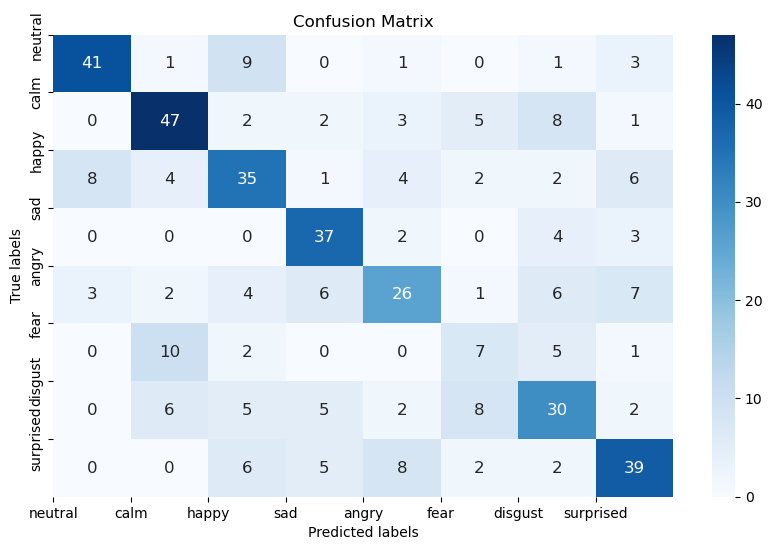

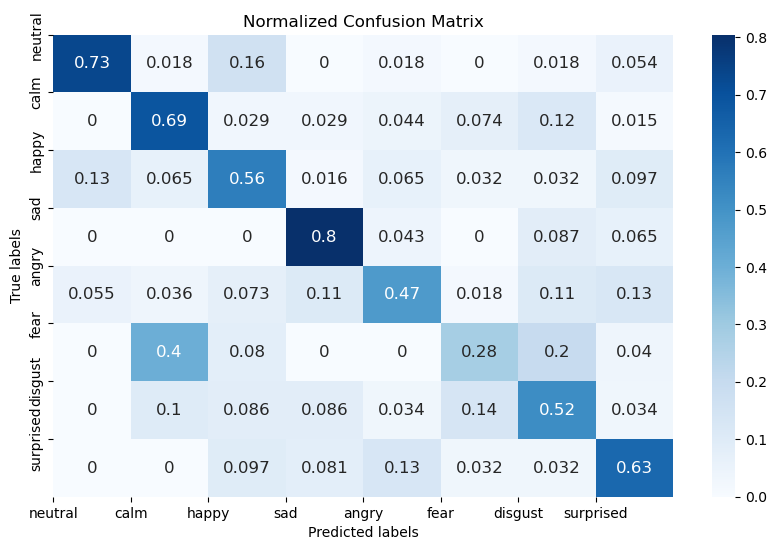

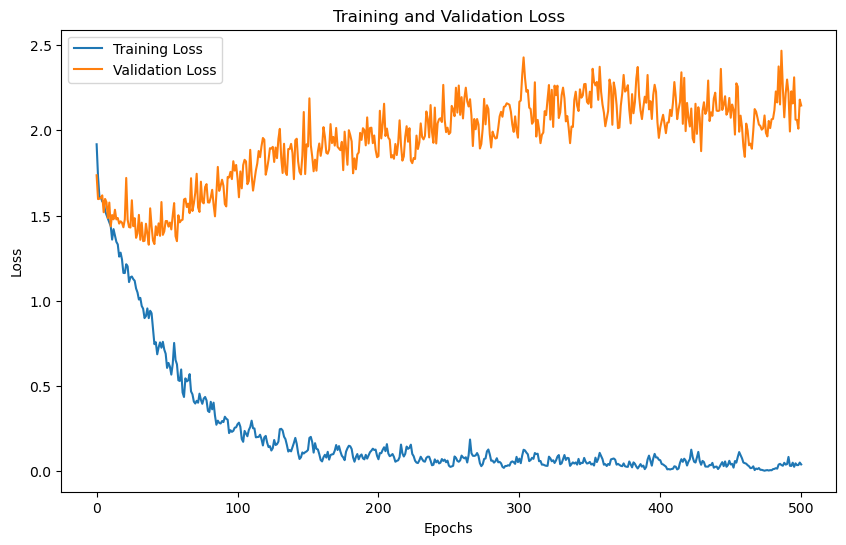

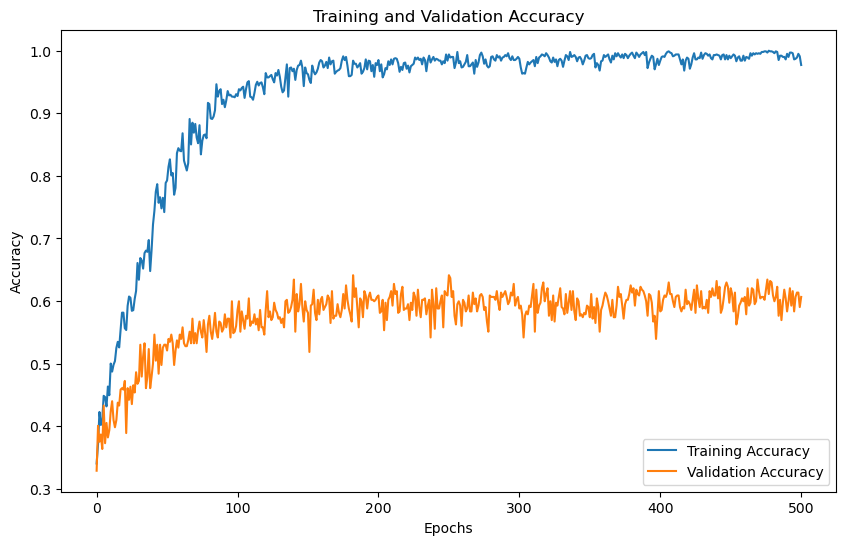

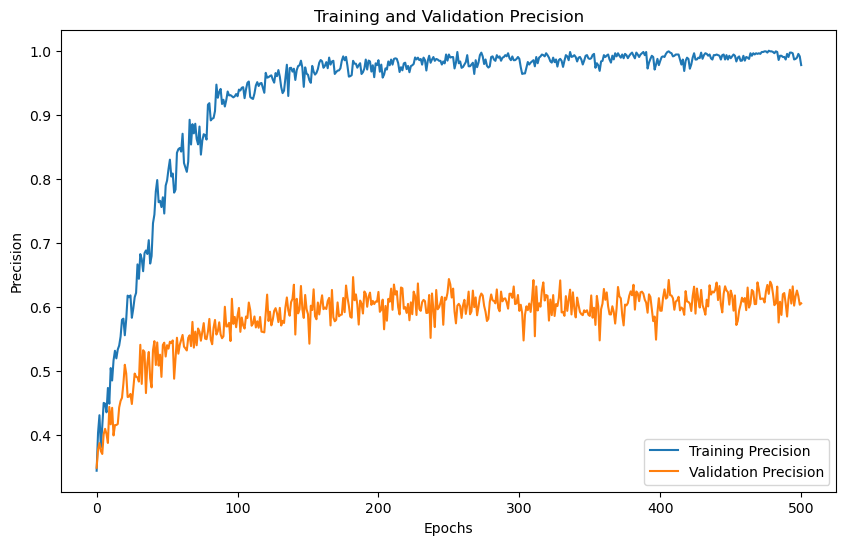

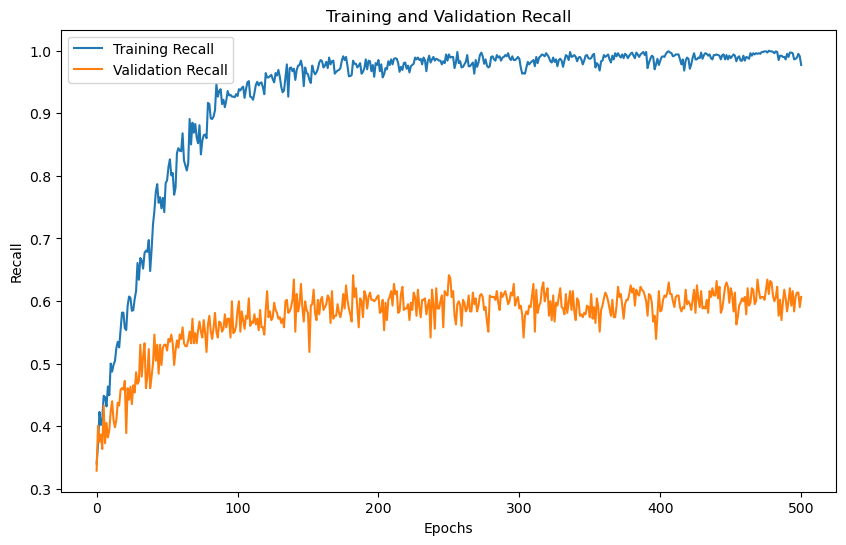

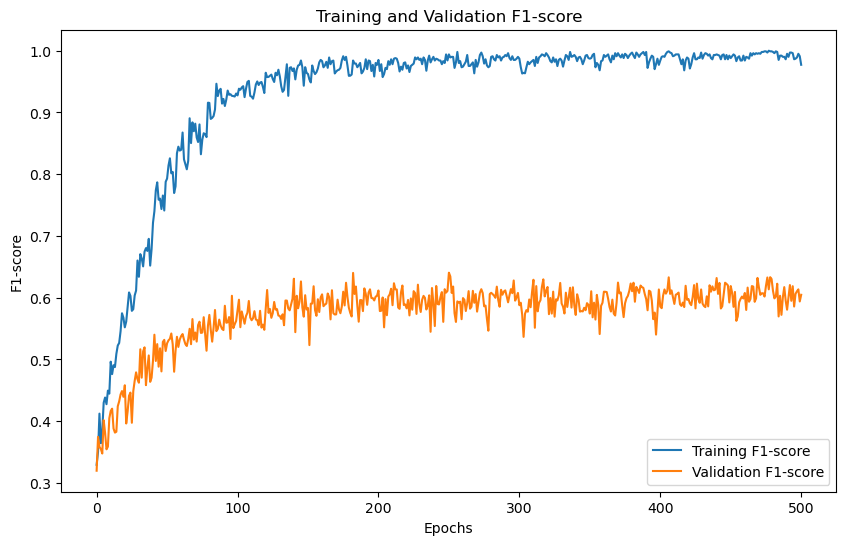

'Model Training and Evaluation Successfully completed'

In [13]:
train_model()